# Etapa 2 · Métricas de avaliação textual

Neste notebook eu calculo as métricas de avaliação textual a partir das tabelas que salvei no fim do `etapa1.ipynb`.

In [17]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", rc={
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#666666", "grid.color": "#e6e6e6",
    "axes.labelcolor": "#191919", "xtick.color": "#666666", "ytick.color": "#666666",
})
CORES = {"train": "#257de0", "validation": "#f47230", "test": "#00b894"}
AZUL = CORES["train"]

DATA_DIR = Path("data")
PALAVRA = r"\w+(?:[-.,']\w+)*"          # mesmo padrão de palavra da Etapa 1

artigos = pd.read_parquet(DATA_DIR / "artigos.parquet")
artigos["split"] = pd.Categorical(artigos["split"], categories=list(CORES))

## 2.1 Diversidade lexical

Começo pela diversidade lexical, que é o quanto um texto varia o vocabulário em vez de repetir as mesmas palavras. Todas as métricas desta parte olham só para a **forma** das palavras: para elas, `car` e `automobile` são palavras diferentes, e `bank` (banco) e `bank` (margem de rio) são a mesma. O significado fica para a parte de diversidade semântica.

### Tokens

Primeiro transformo cada artigo numa lista de palavras em minúsculas, com o mesmo padrão `PALAVRA` da Etapa 1 (números também contam como palavra). Para explicar cada métrica, uso também uma frase de brinquedo, pequena o bastante para dar para fazer as contas à mão.

In [18]:
artigos["tokens"] = artigos["text_limpo"].str.lower().str.findall(PALAVRA)
artigos["n_tokens"] = artigos["tokens"].str.len()

exemplo = "the cat saw the dog and the dog saw the cat".split()

print(f"{len(artigos)} artigos · {artigos['n_tokens'].sum():,} tokens · "
      f"menor artigo: {artigos['n_tokens'].min()} tokens · maior: {artigos['n_tokens'].max():,}")
print("exemplo:", exemplo)

720 artigos · 2,075,214 tokens · menor artigo: 226 tokens · maior: 16,088
exemplo: ['the', 'cat', 'saw', 'the', 'dog', 'and', 'the', 'dog', 'saw', 'the', 'cat']


### TTR (Type-Token Ratio)

**Definição:** o TTR é a métrica mais antiga e mais simples de diversidade lexical (Templin, 1957). Ele divide o número de palavras diferentes (*types*, V) pelo total de palavras (*tokens*, N):

$$\text{TTR} = \frac{V}{N}$$

O valor vai de quase 0, quando o texto repete sempre a mesma palavra, até 1, quando nenhuma palavra se repete.

Na frase de exemplo, `the cat saw the dog and the dog saw the cat`, eu conto 11 tokens e 5 types (`the`, `cat`, `saw`, `dog`, `and`), então o TTR é 5/11 ≈ 0,45.

In [19]:
def ttr(tokens):
    return len(set(tokens)) / len(tokens)

print(f"exemplo: {ttr(exemplo):.3f}  (5/11)")

artigos["ttr"] = artigos["tokens"].map(ttr)

def spearman(a, b):
    return a.rank().corr(b.rank())                     # correlação de Spearman = Pearson dos postos

print(f"TTR por artigo: mediana {artigos['ttr'].median():.3f} · de {artigos['ttr'].min():.3f} a {artigos['ttr'].max():.3f}")
print(f"correlação (Spearman) entre TTR e tamanho do artigo: {spearman(artigos['ttr'], artigos['n_tokens']):.2f}")

exemplo: 0.455  (5/11)
TTR por artigo: mediana 0.353 · de 0.156 a 0.554
correlação (Spearman) entre TTR e tamanho do artigo: -0.82


**Interpretação:** a mediana ficou em 0,35, ou seja, num artigo típico só uma em cada três palavras é nova. O que mais me chamou atenção foi a correlação de **−0,82** com o tamanho: quanto maior o artigo, menor o TTR. Isso acontece porque as palavras comuns (`the`, `of`, `and`) se repetem o texto todo, enquanto as palavras novas aparecem cada vez mais devagar. É o mesmo efeito que fez o train ter TTR menor que validation e test na Etapa 1. Na prática, quando comparo artigos pelo TTR, estou comparando principalmente o **tamanho** deles, e não a diversidade.

**Limitações:**
- Por depender do tamanho, o TTR só serve para comparar textos de tamanho parecido. Essa é a limitação mais conhecida dele, e é por causa dela que surgiram o MATTR e o MTLD.
- Ele só enxerga a forma das palavras: sinônimos contam como palavras diferentes, e a mesma palavra com sentidos diferentes conta como uma só.
- O valor muda conforme a tokenização: passar tudo para minúsculas, contar números como palavras ou juntar `well-known` numa palavra só já altera o resultado.

### MATTR (Moving-Average TTR)

**Definição:** o MATTR (Covington & McFall, 2010) resolve o problema do tamanho calculando o TTR numa janela de tamanho fixo (W palavras), que desliza pelo texto uma palavra por vez. O resultado é a média dos TTRs de todas as janelas:

$$\text{MATTR} = \frac{1}{N - W + 1} \sum_{i=1}^{N-W+1} \text{TTR}(\text{tokens}_{i \ldots i+W-1})$$

Como todas as janelas têm o mesmo tamanho, o TTR deixa de cair só porque o texto cresceu. Escolhi **W = 100**, que cabe até no menor artigo (226 tokens) e ainda gera mais de 100 janelas em cada um.

Na frase de exemplo, com W = 5, as janelas são `the cat saw the dog` (4 types → 0,8), `cat saw the dog and` (5 → 1,0), e assim por diante.

Na implementação, eu não recalculo cada janela do zero: guardo a contagem das palavras da janela atual e, a cada passo, tiro a palavra que sai e coloco a que entra.

In [20]:
JANELA = 100

def mattr(tokens, janela=JANELA):
    cont = Counter(tokens[:janela])                    # palavras da primeira janela
    n_types = [len(cont)]
    for sai, entra in zip(tokens, tokens[janela:]):    # desliza uma palavra por vez
        cont[sai] -= 1
        if cont[sai] == 0:
            del cont[sai]
        cont[entra] += 1
        n_types.append(len(cont))
    return np.mean(n_types) / janela

print(f"exemplo (janela 5): {mattr(exemplo, 5):.3f}")

artigos["mattr"] = artigos["tokens"].map(mattr)

print(f"MATTR por artigo: mediana {artigos['mattr'].median():.3f} · de {artigos['mattr'].min():.3f} a {artigos['mattr'].max():.3f}")
print(f"correlação (Spearman) com o tamanho do artigo: {spearman(artigos['mattr'], artigos['n_tokens']):.2f}")

exemplo (janela 5): 0.800
MATTR por artigo: mediana 0.710 · de 0.588 a 0.777
correlação (Spearman) com o tamanho do artigo: 0.12


**Interpretação:** a mediana ficou em 0,71, ou seja, em qualquer trecho de 100 palavras de um artigo típico, umas 71 são diferentes. E a correlação com o tamanho, que era −0,82 no TTR, caiu para **0,12**. Com isso, agora dá para comparar artigos grandes e pequenos.

**Limitações:**
- O valor depende da janela: um MATTR com janela de 100 e outro com janela de 500 não podem ser comparados, e não existe uma janela "certa".
- Ele mede uma diversidade **local**. Um artigo que repete as mesmas palavras em seções diferentes, mas varia dentro de cada trecho de 100 palavras, ainda fica com MATTR alto.
- O texto precisa ter pelo menos W palavras. Aqui isso não foi problema, porque o menor artigo tem 226.

### MTLD (Measure of Textual Lexical Diversity)

**Definição:** o MTLD mede **quantas palavras seguidas, em média, o texto consegue escrever antes de começar a se repetir demais**. O algoritmo funciona assim:

1. Leio o texto palavra por palavra, calculando o TTR acumulado do trecho atual.
2. Quando o TTR cai até **0,72**, conto 1 **fator** e começo um trecho novo do zero.
3. No fim, o trecho que sobrou entra como um fator parcial: $\frac{1 - \text{TTR}_{\text{resto}}}{1 - 0{,}72}$. Um resto que já caiu quase até 0,72 vale quase um fator inteiro.
4. O MTLD é o nº de tokens dividido pelo nº de fatores.
5. Repito tudo lendo o texto de trás para frente e tiro a média dos dois sentidos.

Quanto **maior** o MTLD, mais palavras o texto consegue escrever antes de se repetir, ou seja, mais diverso ele é. O limiar de 0,72 é o valor que os autores testaram e recomendam. Como o resultado é o comprimento médio de um trecho, ele não depende do tamanho total do texto.

Logo abaixo mostro o passo a passo nos primeiros tokens de um artigo: cada palavra aparece com o TTR acumulado até ela, e o `‖` marca o ponto em que o TTR chegou a 0,72 e um fator foi fechado.

In [21]:
LIMIAR = 0.72

def mtld_sentido(tokens, limiar=LIMIAR):
    fatores, tipos, n = 0, set(), 0
    for t in tokens:
        n += 1
        tipos.add(t)
        if len(tipos) / n <= limiar:                   # o trecho ficou repetitivo: fecha um fator
            fatores += 1
            tipos, n = set(), 0
    if n > 0:                                          # fator parcial do trecho que sobrou
        fatores += (1 - len(tipos) / n) / (1 - limiar)
    return len(tokens) / fatores

def mtld(tokens, limiar=LIMIAR):
    return (mtld_sentido(tokens, limiar) + mtld_sentido(tokens[::-1], limiar)) / 2

def passo_a_passo(tokens, limiar=LIMIAR):
    saida, tipos, n = [], set(), 0
    for t in tokens:
        n += 1
        tipos.add(t)
        saida.append(f"{t}({len(tipos) / n:.2f})")
        if len(tipos) / n <= limiar:
            saida.append("‖")
            tipos, n = set(), 0
    print(" ".join(saida))

passo_a_passo(artigos.loc[0, "tokens"][:60])

senjō(1.00) no(1.00) valkyria(1.00) 3(1.00) unrecorded(1.00) chronicles(1.00) japanese(1.00) 戦場のヴァルキュリア3(1.00) lit(1.00) valkyria(0.90) of(0.91) the(0.92) battlefield(0.92) 3(0.86) commonly(0.87) referred(0.88) to(0.88) as(0.89) valkyria(0.84) chronicles(0.80) iii(0.81) outside(0.82) japan(0.83) is(0.83) a(0.84) tactical(0.85) role-playing(0.85) video(0.86) game(0.86) developed(0.87) by(0.87) sega(0.88) and(0.88) media.vision(0.88) for(0.89) the(0.86) playstation(0.86) portable(0.87) released(0.87) in(0.88) january(0.88) 2011(0.88) in(0.86) japan(0.84) it(0.84) is(0.83) the(0.81) third(0.81) game(0.80) in(0.78) the(0.76) valkyria(0.75) series(0.75) employing(0.76) the(0.75) same(0.75) fusion(0.75) of(0.74) tactical(0.73) and(0.72) ‖


In [22]:
artigos["mtld"] = artigos["tokens"].map(mtld)

print(f"MTLD por artigo: mediana {artigos['mtld'].median():.1f} · de {artigos['mtld'].min():.1f} a {artigos['mtld'].max():.1f}")
print(f"correlação (Spearman) com o tamanho do artigo: {spearman(artigos['mtld'], artigos['n_tokens']):.2f}")

MTLD por artigo: mediana 85.5 · de 38.4 a 147.6
correlação (Spearman) com o tamanho do artigo: 0.16


**Interpretação:** no passo a passo, o primeiro fator só fecha depois de 59 palavras. Faz sentido: o começo de um artigo apresenta o assunto com muitas palavras novas, e o TTR vai caindo devagar até chegar a 0,72. A mediana do MTLD ficou em **85,5**, ou seja, num artigo típico o texto consegue em média umas 85 palavras seguidas antes de ficar repetitivo. Os valores vão de 38, no artigo mais repetitivo, a 148, no mais diverso, e a correlação com o tamanho é de apenas **0,16**.

**Limitações:**
- O limiar de 0,72 foi definido pelos autores a partir de textos em inglês. Com outro limiar os valores mudam (eles indicam a faixa de 0,66 a 0,75).
- Em textos curtos o MTLD fica instável: com poucos fatores, o fator parcial do fim pesa muito. Os autores recomendam textos com pelo menos 100 palavras.
- O fator parcial é uma aproximação, que supõe que o TTR continuaria caindo no mesmo ritmo.
- Assim como as outras métricas desta parte, ele só enxerga a forma das palavras.

### Distinct-N

**Definição:** o Distinct-N (Li et al., 2016) é a fração de n-gramas únicos, sendo um n-grama uma sequência de n palavras seguidas:

$$\text{Distinct-}n = \frac{\text{nº de n-gramas diferentes}}{\text{nº total de n-gramas}}$$

O Distinct-1 é o próprio TTR. Já o Distinct-2 e o Distinct-3 olham pares e trios de palavras, então medem também a repetição de **expressões**, e não só de palavras soltas. A métrica nasceu para avaliar texto gerado por modelos: respostas de chatbot muito repetitivas, como "I don't know", têm Distinct-N baixo.

Na frase de exemplo, os bigramas são `the cat`, `cat saw`, `saw the`, `the dog`, `dog and`, `and the`, `the dog`, `dog saw`, `saw the`, `the cat`: 10 no total e 7 diferentes, então o Distinct-2 é 0,7.

Como o Distinct-N tem o mesmo problema de tamanho do TTR, calculei de dois jeitos:
- **por split**: com o split inteiro e com todos cortados no tamanho do menor (validation, ~178 mil tokens);
- **por artigo**: como a média em blocos de 200 tokens seguidos.

In [23]:
def ngramas(tokens, n):
    return list(zip(*(tokens[i:] for i in range(n))))

def distinct(tokens, n):
    g = ngramas(tokens, n)
    return len(set(g)) / len(g)

print(f"exemplo: Distinct-1 = {distinct(exemplo, 1):.3f} · Distinct-2 = {distinct(exemplo, 2):.3f}")

por_split = artigos.groupby("split", observed=True)["tokens"].sum()     # junta os artigos de cada split
menor = por_split.str.len().min()
linhas = {}
for split, tokens in por_split.items():
    for nome, t in [("inteiro", tokens), (f"primeiros {menor:,}", tokens[:menor])]:
        linhas[(split, nome)] = {"tokens": len(t), **{f"distinct_{n}": distinct(t, n) for n in (1, 2, 3)}}
pd.DataFrame(linhas).T.round(3)

exemplo: Distinct-1 = 0.455 · Distinct-2 = 0.700


tokens  distinct_1  distinct_2  distinct_3
train      inteiro            1697200.0       0.046       0.420       0.791
           primeiros 177,909   177909.0       0.113       0.594       0.889
validation inteiro             177909.0       0.108       0.583       0.877
           primeiros 177,909   177909.0       0.108       0.583       0.877
test       inteiro             200105.0       0.103       0.572       0.872
           primeiros 177,909   177909.0       0.107       0.579       0.875

In [24]:
BLOCO = 200

def distinct_blocos(tokens, n, bloco=BLOCO):
    blocos = [tokens[i:i + bloco] for i in range(0, len(tokens) - bloco + 1, bloco)]
    return np.mean([distinct(b, n) for b in blocos])

for n in (1, 2, 3):
    artigos[f"distinct_{n}"] = artigos["tokens"].map(lambda t: distinct_blocos(t, n))
artigos["distinct_2_inteiro"] = artigos["tokens"].map(lambda t: distinct(t, 2))

print(artigos[["distinct_1", "distinct_2", "distinct_3"]].describe().loc[["mean", "50%", "min", "max"]].round(3))
print(f"\ncorrelação (Spearman) com o tamanho: Distinct-2 no artigo inteiro = {spearman(artigos['distinct_2_inteiro'], artigos['n_tokens']):.2f} · "
      f"em blocos de {BLOCO} = {spearman(artigos['distinct_2'], artigos['n_tokens']):.2f}")

      distinct_1  distinct_2  distinct_3
mean       0.615       0.929       0.983
50%        0.619       0.934       0.987
min        0.445       0.781       0.894
max        0.692       0.976       0.999

correlação (Spearman) com o tamanho: Distinct-2 no artigo inteiro = -0.52 · em blocos de 200 = 0.28


**Interpretação:**
- **Por split:** olhando o split inteiro, o train parece muito menos diverso (Distinct-1 de 0,046, contra 0,108 do validation). Mas quando corto todos no mesmo tamanho (177.909 tokens), o train sobe para 0,113 e fica praticamente igual aos outros (0,108 e 0,107). A diferença era **só o tamanho**, como já tinha aparecido no TTR da Etapa 1, e o mesmo acontece com o Distinct-2 e o Distinct-3.
- **Por artigo (blocos de 200):** as médias ficaram em 0,62 para o Distinct-1, 0,93 para o Distinct-2 e 0,98 para o Distinct-3. Em texto de enciclopédia quase nenhum par ou trio de palavras se repete dentro de 200 palavras, então o Distinct-3 fica perto do teto e quase não diferencia os artigos.
- No artigo inteiro, o Distinct-2 tem correlação de −0,52 com o tamanho. Nos blocos de 200, essa dependência some (0,28, e com sinal positivo).

**Limitações:**
- Ele tem o mesmo problema de tamanho do TTR, então só dá para comparar usando blocos ou cortes de tamanho fixo.
- Foi criado para texto **gerado** por modelos, em que repetição é um defeito comum. Em texto escrito por pessoas, a partir de n = 3 ele satura perto de 1 e perde a capacidade de diferenciar os textos.
- No cálculo por split, alguns n-gramas atravessam a fronteira entre um artigo e o seguinte e acabam sendo n-gramas "falsos". Mas são poucos perto de milhões de tokens.

### Comparando as métricas lexicais

Com as quatro métricas calculadas para os 720 artigos, ainda quero responder duas perguntas: quais delas dependem do tamanho do texto, e se elas concordam entre si.

**Gráfico 2.1** · As métricas dependem do tamanho do artigo?

A principal crítica ao TTR é depender do tamanho do texto, e eu usei o MATTR, o MTLD e o Distinct-N em blocos justamente para contornar isso. Com este gráfico eu confiro se deu certo.

- cada ponto é um artigo, com o tamanho no eixo x (em escala log) e o valor da métrica no eixo y, colorido pelo split. No título de cada painel coloquei a correlação de Spearman com o tamanho: perto de 0, a métrica não depende do tamanho; perto de −1 ou de 1, depende muito.

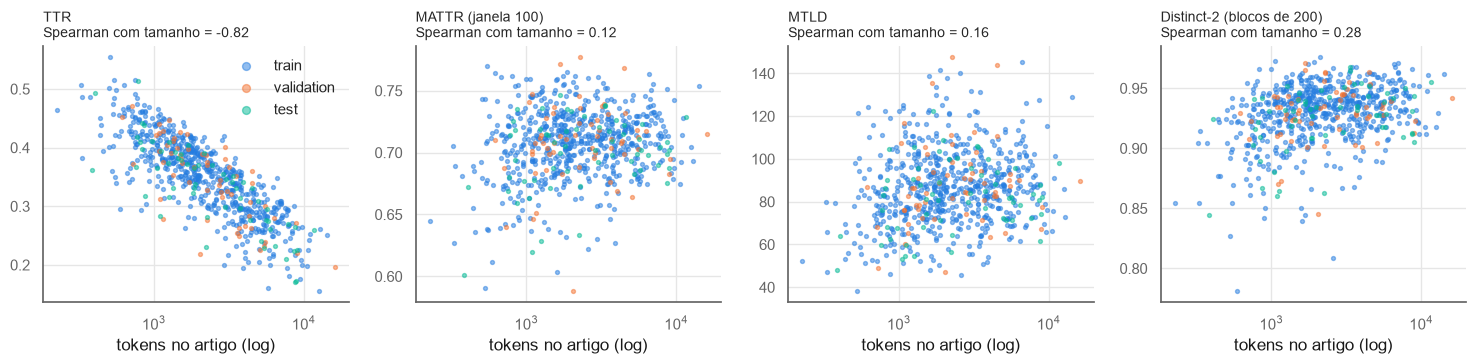

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharex=True)
for ax, (col, nome) in zip(axes, [("ttr", "TTR"), ("mattr", f"MATTR (janela {JANELA})"),
                                  ("mtld", "MTLD"), ("distinct_2", f"Distinct-2 (blocos de {BLOCO})")]):
    for split, cor in CORES.items():
        parte = artigos[artigos["split"] == split]
        ax.scatter(parte["n_tokens"], parte[col], s=8, alpha=0.5, color=cor, label=split)
    ax.set_xscale("log")
    ax.set(xlabel="tokens no artigo (log)")
    ax.set_title(f"{nome}\nSpearman com tamanho = {spearman(artigos[col], artigos['n_tokens']):.2f}", loc="left", fontsize=10)
axes[0].legend(frameon=False, markerscale=2)
plt.tight_layout()
plt.show()

- O TTR desce em diagonal (−0,82): só de saber o tamanho do artigo, já dá para adivinhar o TTR dele.
- O MATTR (0,12), o MTLD (0,16) e o Distinct-2 em blocos (0,28) formam nuvens quase horizontais, então a dependência do tamanho praticamente desapareceu.
- A pequena correlação positiva que sobra pode ser real, e não um defeito das métricas: vários artigos curtos são de tipos repetitivos, como estradas e listas de prêmios, enquanto os longos costumam ser textos narrativos mais elaborados.
- Os três splits ficam misturados nas nuvens, então nenhum deles é mais ou menos diverso que os outros.

**Gráfico 2.2** · As métricas concordam entre si?

- cada célula mostra a correlação de Spearman entre duas métricas nos 720 artigos. Vermelho escuro (perto de 1) quer dizer que as duas ordenam os artigos quase do mesmo jeito; branco (perto de 0), que não têm relação; e azul, que andam em sentidos opostos.

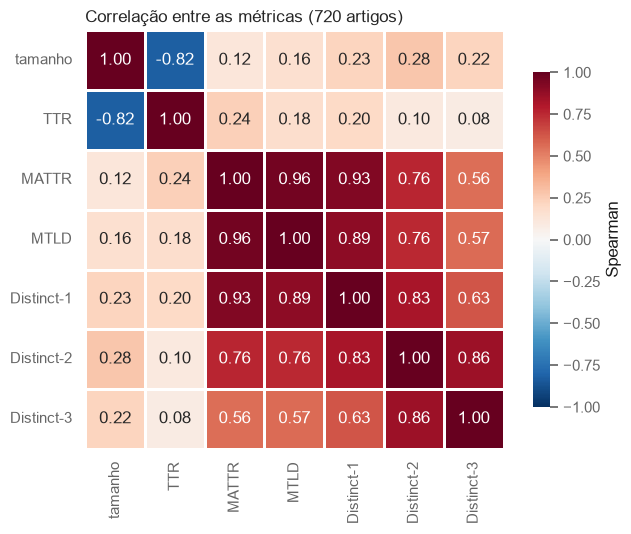

In [26]:
metricas = {"n_tokens": "tamanho", "ttr": "TTR", "mattr": "MATTR", "mtld": "MTLD",
            "distinct_1": "Distinct-1", "distinct_2": "Distinct-2", "distinct_3": "Distinct-3"}
corr = artigos[list(metricas)].rank().corr().rename(index=metricas, columns=metricas)

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            linewidths=1, linecolor="white", cbar_kws={"label": "Spearman", "shrink": 0.8}, ax=ax)
ax.set_title("Correlação entre as métricas (720 artigos)", loc="left")
plt.tight_layout()
plt.show()

- **O MATTR e o MTLD medem quase a mesma coisa (0,96).** Os dois controlam o tamanho de jeitos diferentes, um com janela fixa e o outro com o comprimento médio dos trechos, e mesmo assim ordenam os artigos do mesmo jeito. Por isso, daqui em diante uso só uma delas como métrica principal: o **MTLD**, porque ele não depende de escolher uma janela.
- **O TTR discorda de todas as outras (0,08 a 0,24)** e só se correlaciona com o tamanho (−0,82). Se eu fizesse um ranking dos "artigos mais diversos" pelo TTR, chegaria a uma conclusão diferente da que o MTLD dá. É um exemplo concreto de métricas que levam a conclusões contraditórias.
- **Quanto maior o n, mais o Distinct-N se afasta do MTLD** (0,89 → 0,76 → 0,57). O Distinct-1 em blocos é praticamente um MATTR com outra janela. Já o Distinct-3 mede outra coisa, a repetição de expressões, mas como ele está perto do teto, essa informação acaba sendo pequena.

## Diversidade semântica

As métricas lexicais olham a **forma** das palavras dentro de cada texto. Nesta parte, a pergunta passa a ser sobre o **conteúdo**: os textos falam de coisas diferentes ou parecidas? A atividade pede duas abordagens:

- **Similaridade por embeddings:** um modelo de linguagem transforma cada texto num vetor que representa o seu significado. Textos com significado parecido ficam com vetores próximos, mesmo quando usam palavras diferentes.
- **Self-BLEU:** mede o quanto os textos **repetem as sequências de palavras uns dos outros**. Apesar de aparecer junto com diversidade semântica, ele compara n-gramas, ou seja, forma. Por isso achei interessante ver se ele concorda com os embeddings.

Diferente da parte lexical, aqui a comparação é principalmente **entre textos**: o corpus é diverso se os artigos são diferentes uns dos outros.

### Similaridade por embeddings

**Definição:** usei o modelo `all-MiniLM-L6-v2`, um Sentence-BERT, que transforma cada texto num vetor de **384 números**.

Para medir a proximidade entre dois vetores u e v, uso a **similaridade cosseno**, que é o cosseno do ângulo entre eles:

$$\cos(u, v) = \frac{u \cdot v}{\lVert u \rVert \, \lVert v \rVert}$$

Ela vai de −1 a 1: perto de 1, os textos têm o mesmo sentido; perto de 0, não têm relação. Como os vetores estão normalizados (tamanho 1), o cosseno é simplesmente o produto escalar. A partir disso, defino a **diversidade semântica** de um conjunto de textos como **1 − similaridade média entre os pares**.

No exemplo abaixo, as frases 1 e 2 dizem quase a mesma coisa com palavras diferentes (`cat`/`kitten`, `mat`/`rug`), e a 3 fala de outro assunto. Na tabela, comparo a similaridade dos embeddings com a fração de palavras em comum (Jaccard), que é o que uma métrica lexical enxergaria.

In [27]:
from sentence_transformers import SentenceTransformer

modelo = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")

frases_ex = ["The cat sat on the mat.", "A kitten was resting on the rug.", "The stock market fell sharply today."]
E_ex = modelo.encode(frases_ex, normalize_embeddings=True)

def jaccard(a, b):
    a, b = set(a.lower().strip(".").split()), set(b.lower().strip(".").split())
    return len(a & b) / len(a | b)

pd.DataFrame([{"par": f"{i + 1} × {j + 1}", "cosseno (embedding)": E_ex[i] @ E_ex[j],
               "palavras em comum (Jaccard)": jaccard(frases_ex[i], frases_ex[j])}
              for i, j in [(0, 1), (0, 2), (1, 2)]]).round(2)

c:\Users\jairoNeto\Desktop\kunumi\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4189.55it/s]


,par,cosseno (embedding),palavras em comum (Jaccard)
0,1 × 2,0.63,0.20
1,1 × 3,0.07,0.10
2,2 × 3,0.11,0.08


- O modelo só lê até **256 *wordpieces*** (pedaços de palavra, umas 190 palavras) e corta o que passar disso. Como os artigos têm em média umas 2.900 palavras, dividi cada um em **blocos de 150 palavras**. Cada bloco vira um embedding, e o vetor do artigo é a média dos vetores dos seus blocos. Sobras com menos de 50 palavras no fim do artigo eu descartei.

In [28]:
BLOCO_EMB = 150

linhas = []
for i_art, a in enumerate(artigos.itertuples()):
    palavras = a.text_limpo.split()
    for k, ini in enumerate(range(0, len(palavras), BLOCO_EMB)):
        pedaco = palavras[ini:ini + BLOCO_EMB]
        if k == 0 or len(pedaco) >= 50:                # descarta sobras muito curtas no fim
            linhas.append((i_art, k, " ".join(pedaco)))
blocos = pd.DataFrame(linhas, columns=["art", "bloco", "texto"])

CACHE = DATA_DIR / "embeddings_blocos.npy"
if CACHE.exists():
    E = np.load(CACHE)
else:
    E = modelo.encode(blocos["texto"].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=True)
    np.save(CACHE, E)
assert len(E) == len(blocos), "cache desatualizado: apague data/embeddings_blocos.npy"

V = np.zeros((len(artigos), E.shape[1]))
np.add.at(V, blocos["art"].to_numpy(), E)              # soma os blocos de cada artigo
V /= np.linalg.norm(V, axis=1, keepdims=True)          # média normalizada = vetor do artigo
S = V @ V.T                                            # similaridade cosseno entre todos os pares de artigos

print(f"{len(blocos):,} blocos · {blocos.groupby('art').size().median():.0f} blocos por artigo (mediana) · embeddings {E.shape}")

14,281 blocos · 14 blocos por artigo (mediana) · embeddings (14281, 384)


Com os vetores prontos, meço a similaridade em dois níveis:
- **entre artigos:** são 720 × 719 / 2 = 258.840 pares de artigos. Isso mostra se o corpus fala de muitas coisas diferentes.
- **dentro do artigo:** a média entre os blocos de um mesmo artigo. Isso mostra se o artigo fica num assunto só ou muda de assunto ao longo do texto. Chamo de **diversidade semântica interna** o valor 1 − essa média.

Para saber se um cosseno é "alto", também comparo com pares de blocos sorteados de artigos diferentes. Eles servem de **linha de base**: é a similaridade entre dois textos sem relação nenhuma.

In [29]:
pares_art = S[np.triu_indices(len(S), k=1)]

grupos = blocos.groupby("art").indices
def sim_interna(idx):
    M = E[idx] @ E[idx].T
    return M[np.triu_indices(len(idx), k=1)].mean()
artigos["sim_interna"] = [sim_interna(grupos[i]) for i in range(len(artigos))]
artigos["div_semantica"] = 1 - artigos["sim_interna"]

rng = np.random.default_rng(0)
a, b = rng.integers(0, len(blocos), (2, 200_000))
diferentes = blocos["art"].to_numpy()[a] != blocos["art"].to_numpy()[b]
base = np.einsum("ij,ij->i", E[a[diferentes]], E[b[diferentes]])   # cosseno de blocos de artigos diferentes

print(f"entre artigos: similaridade média {pares_art.mean():.3f} (mediana {np.median(pares_art):.3f}) → diversidade semântica do corpus = {1 - pares_art.mean():.3f}")
print(f"blocos de artigos diferentes (linha de base): média {base.mean():.3f}")
print(f"blocos do mesmo artigo: média {artigos['sim_interna'].mean():.3f} (de {artigos['sim_interna'].min():.3f} a {artigos['sim_interna'].max():.3f})")
print(f"pares de artigos com cosseno > 0,7: {(pares_art > 0.7).sum()} · > 0,8: {(pares_art > 0.8).sum()}")  

entre artigos: similaridade média 0.058 (mediana 0.035) → diversidade semântica do corpus = 0.942
blocos de artigos diferentes (linha de base): média 0.030
blocos do mesmo artigo: média 0.528 (de 0.257 a 0.848)
pares de artigos com cosseno > 0,7: 275 · > 0,8: 42


**Gráfico 2.3** · O quanto os artigos se parecem?

Aqui eu quis ver duas coisas: se o corpus tem muitos artigos parecidos entre si, o que indicaria pouca diversidade entre artigos, e quanto vale a similaridade entre blocos do mesmo artigo comparada com a de textos sem relação. Isso me dá uma noção do que é um cosseno "alto" para este modelo.

- na esquerda, cada barra é uma faixa de similaridade e a altura é quantos pares de artigos caem nela. Na direita, em cinza, está a similaridade entre blocos sorteados de artigos diferentes (a linha de base) e, em laranja, a similaridade média entre os blocos de cada artigo. As duas estão em densidade (área total = 1), para dar para comparar grupos de tamanhos diferentes.

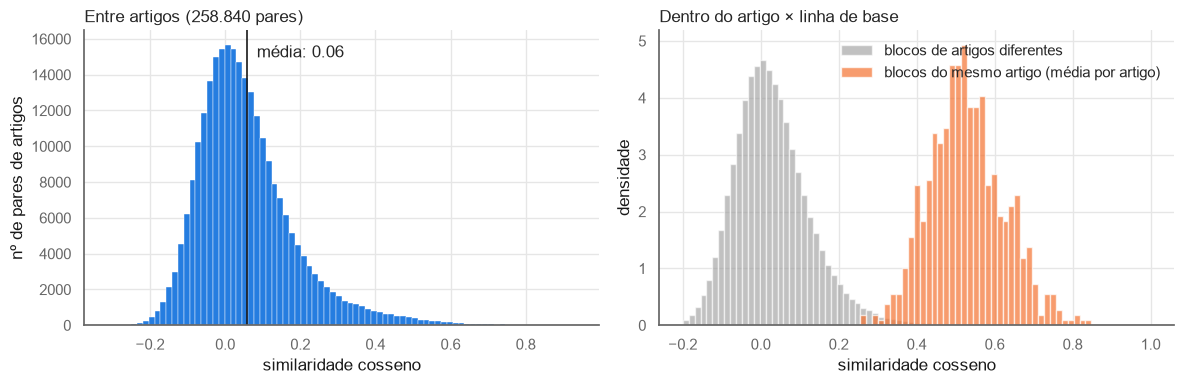

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(pares_art, bins=80, color=AZUL, edgecolor="white", linewidth=0.3)
axes[0].axvline(pares_art.mean(), color="#191919", linewidth=1.2)
axes[0].text(pares_art.mean(), axes[0].get_ylim()[1] * 0.95, f"  média: {pares_art.mean():.2f}", va="top")
axes[0].set(xlabel="similaridade cosseno", ylabel="nº de pares de artigos")
axes[0].set_title("Entre artigos (258.840 pares)", loc="left")

bins = np.linspace(-0.2, 1, 80)
axes[1].hist(base, bins=bins, density=True, alpha=0.6, color="#999999", label="blocos de artigos diferentes")
axes[1].hist(artigos["sim_interna"], bins=bins, density=True, alpha=0.7, color=CORES["validation"], label="blocos do mesmo artigo (média por artigo)")
axes[1].set(xlabel="similaridade cosseno", ylabel="densidade")
axes[1].set_title("Dentro do artigo × linha de base", loc="left")
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

- Entre artigos, a similaridade média é de só **0,06** (mediana de 0,035). A maioria dos pares fica entre −0,1 e 0,2, ou seja, quase todos os artigos falam de coisas sem relação entre si. Com isso, a diversidade semântica do corpus (1 − média) fica em **0,94**.
- A cauda à direita é pequena, mas existe: 275 pares passam de 0,7 e 42 passam de 0,8.
- Na direita, as duas distribuições quase não se encostam: blocos sem relação ficam em torno de 0,03, e blocos do mesmo artigo, em torno de 0,53. Ou seja, o modelo separa bem "mesmo assunto" de "outro assunto".
- Mesmo dentro de um artigo, a similaridade fica longe de 1 (de 0,26 a 0,85), porque seções diferentes do mesmo artigo tratam de aspectos diferentes do assunto (enredo, produção, recepção).

**Gráfico 2.4** · Alta diversidade lexical implica alta diversidade semântica?

Essa é uma das perguntas da Etapa 4, e aqui eu já consigo testá-la. Para cada artigo, comparo o MTLD (quantas palavras o texto escreve antes de se repetir) com a diversidade semântica interna (o quanto os blocos do artigo falam de coisas diferentes).

- cada ponto é um artigo, com o MTLD no eixo x e a diversidade semântica interna no eixo y. Se uma coisa implicasse a outra, os pontos formariam uma diagonal subindo. Nas tabelas abaixo do gráfico estão os 5 artigos com menor e os 5 com maior diversidade semântica interna.

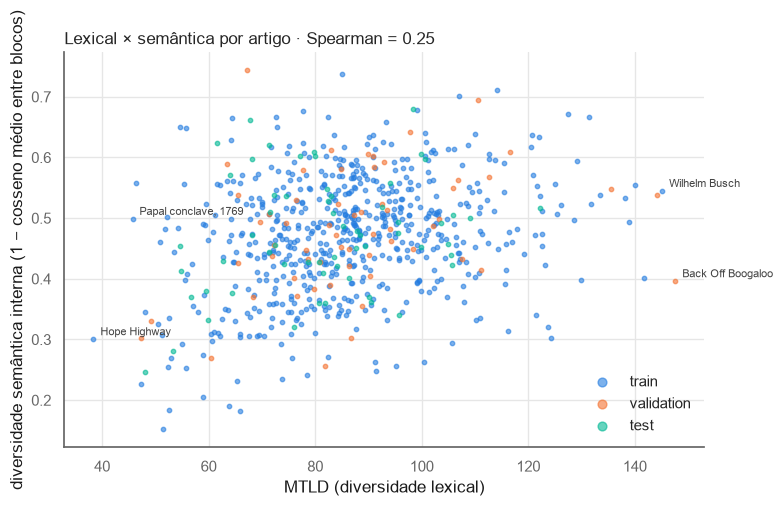

Spearman da diversidade semântica interna com o tamanho: 0.45


,artigo,n_tokens,mtld,div_semantica
240,New Jersey Route 65,590,51.449,0.152
376,New York State Route 164,333,65.856,0.182
115,M-122 (Michigan highway),226,52.449,0.185
24,WASP-44,603,63.832,0.191
379,New York State Route 185,549,58.899,0.206


,artigo,n_tokens,mtld,div_semantica
604,"Meridian, Mississippi",8943,67.209,0.743
408,A Month in the Country (film),1734,85.090,0.738
148,You Only Live Twice (film),3449,114.038,0.711
367,Chapter 1 (House of Cards),2570,106.912,0.702
656,Horrible Bosses,4544,110.580,0.695


In [31]:
fig, ax = plt.subplots(figsize=(8, 5))
for split, cor in CORES.items():
    parte = artigos[artigos["split"] == split]
    ax.scatter(parte["mtld"], parte["div_semantica"], s=10, alpha=0.6, color=cor, label=split)
for titulo in ["Hope Highway", "Back Off Boogaloo", "Wilhelm Busch", "Papal conclave, 1769"]:
    linha = artigos[artigos["artigo"] == titulo].iloc[0]
    ax.annotate(titulo, (linha["mtld"], linha["div_semantica"]), xytext=(5, 3), textcoords="offset points", fontsize=8, color="#444444")
ax.set(xlabel="MTLD (diversidade lexical)", ylabel="diversidade semântica interna (1 − cosseno médio entre blocos)")
ax.set_title(f"Lexical × semântica por artigo · Spearman = {spearman(artigos['mtld'], artigos['div_semantica']):.2f}", loc="left")
ax.legend(frameon=False, markerscale=2)
plt.tight_layout()
plt.show()

print(f"Spearman da diversidade semântica interna com o tamanho: {spearman(artigos['div_semantica'], artigos['n_tokens']):.2f}")
cols = ["artigo", "n_tokens", "mtld", "div_semantica"]
display(artigos.nsmallest(5, "div_semantica")[cols].round(3), artigos.nlargest(5, "div_semantica")[cols].round(3))

- A correlação é de só **0,25**. Existe uma tendência fraca, mas a nuvem é larga: artigos com o mesmo MTLD (~85) vão de 0,2 a 0,7 de diversidade semântica.
- Os artigos destacados ajudam a entender o porquê. `Back Off Boogaloo` tem o maior MTLD (vocabulário muito variado), mas diversidade semântica abaixo da média (0,40): é um artigo sobre uma música, que fala dela o tempo todo, só que com palavras diferentes. Já `Papal conclave, 1769` tem MTLD baixo, porque repete nomes e títulos de cardeais, mas diversidade semântica de ~0,5, porque passa pela morte do papa, pela política entre as cortes e pelas votações.
- Os de menor diversidade semântica são estradas (`New Jersey Route 65`, `New York State Route 164`, `M-122`) e um exoplaneta (`WASP-44`): textos curtos, de um assunto só, escritos em fórmula. Os de maior são uma cidade (`Meridian, Mississippi`, que passa por história, economia e cultura) e filmes e séries, em que enredo, elenco, produção e recepção são assuntos bem diferentes.
- Então a resposta é **não**: variar as palavras não é o mesmo que variar o assunto. As duas medidas capturam coisas diferentes e se complementam.
- Só um cuidado: a diversidade semântica interna tem correlação de **0,45 com o tamanho** do artigo. Artigos longos têm mais seções e cobrem mais subtemas, então parte dessa relação pode vir do tamanho (o MTLD tem só 0,16 com o tamanho).

**Interpretação:** pelos embeddings, o WikiText-2 é semanticamente muito diverso entre artigos (0,94), com alguns grupos de artigos feitos no mesmo molde. Dentro de cada artigo, os blocos são bem mais parecidos entre si (0,53) do que blocos de artigos diferentes (0,03), mas não chegam a ser idênticos, porque cada seção trata de um aspecto do assunto.

**Limitações:**
- O valor absoluto do cosseno depende do modelo. Em modelos derivados do BERT, os vetores tendem a se concentrar numa região estreita do espaço, então dois textos sem relação nem sempre dão 0. Aqui a linha de base ficou em 0,03, mas outro modelo teria outra escala. Por isso só faz sentido comparar valores do mesmo modelo, de preferência contra uma linha de base.
- O modelo lê no máximo 256 wordpieces, e foi por isso que dividi os artigos em blocos de 150 palavras. Como o vetor do artigo é a média dos blocos, assuntos que aparecem só numa parte do artigo acabam diluídos.
- A diversidade semântica interna depende do tamanho do artigo (0,45), assim como o TTR na parte lexical.
- O modelo foi treinado com pares de frases da internet e tem seus próprios vieses: ele pode achar parecidos textos que só compartilham o gênero ("artigo sobre um filme") ou o estilo, e não o assunto específico.
- O `all-MiniLM-L6-v2` é um modelo pequeno, que escolhi por rodar em CPU. Modelos maiores podem separar melhor as nuances de significado.

### Self-BLEU

**Definição:** o BLEU (Papineni et al., 2002) foi criado para avaliar tradução automática. Ele compara um texto **candidato** com textos de **referência**, contando quantos n-gramas do candidato aparecem nas referências. Para n de 1 a 4:

$$p_n = \frac{\text{nº de n-gramas do candidato que aparecem nas referências (cortado no máximo que aparece numa referência)}}{\text{nº de n-gramas do candidato}}$$

$$\text{BLEU} = \text{BP} \cdot \exp\left(\frac{1}{4} \sum_{n=1}^{4} \log p_n\right)$$

O "cortado" impede que um candidato como `the the the` ganhe 3 acertos só porque `the` aparece uma vez na referência. Já o BP (*brevity penalty*) penaliza candidatos mais curtos que as referências.

O **Self-BLEU** (Zhu et al., 2018) usa o BLEU para medir diversidade: **cada texto vira candidato e todos os outros viram referências**, e o resultado é a média. Um Self-BLEU alto quer dizer que os textos repetem as sequências de palavras uns dos outros, ou seja, que há **pouca diversidade**. Ele foi pensado para avaliar modelos que geram texto, que tendem a repetir as mesmas frases prontas.

Na minha implementação, três detalhes merecem atenção:
- **Suavização:** frases curtas muitas vezes não têm nenhum 4-grama em comum, e log(0) não existe. Quando um $p_n$ dá 0, troco o numerador por 0,1 (método 1 de Chen & Cherry, 2014).
- **BP = 1:** com centenas de referências, quase sempre existe uma do mesmo tamanho do candidato, então a penalidade desaparece.
- **Eficiência:** comparar cada texto com todos os outros, um por um, é lento (N²). Em vez disso, para cada n-grama eu guardo a **maior e a segunda maior contagem** entre todos os textos. O "máximo nas referências" de um texto é a maior contagem, ou a segunda maior, se a maior for dele mesmo.

No exemplo abaixo, as duas primeiras frases têm quase tudo em comum, e a terceira não tem nada a ver com elas.

In [32]:
import math
from collections import defaultdict

def self_bleu(textos, n_max=4, eps=0.1):
    conts = [[Counter(ngramas(t, n)) for n in range(1, n_max + 1)] for t in textos]
    # para cada n-grama: [maior contagem, texto que tem a maior, segunda maior]
    top = [defaultdict(lambda: [0, -1, 0]) for _ in range(n_max)]
    for i, cs in enumerate(conts):
        for n, c in enumerate(cs):
            for g, k in c.items():
                m = top[n][g]
                if k > m[0]:
                    m[2], m[0], m[1] = m[0], k, i
                elif k > m[2]:
                    m[2] = k
    notas = []
    for i, cs in enumerate(conts):
        logs = []
        for n, c in enumerate(cs):
            total = sum(c.values())
            if total == 0:                              # texto curto demais para ter n-gramas desse tamanho
                logs.append(math.log(eps))
                continue
            # máximo nas OUTRAS referências: a segunda maior contagem se a maior for do próprio texto
            acertos = sum(min(k, top[n][g][2] if top[n][g][1] == i else top[n][g][0]) for g, k in c.items())
            logs.append(math.log((acertos or eps) / total))
        notas.append(math.exp(sum(logs) / n_max))
    return np.array(notas)

ex = [s.split() for s in ["the cat sat on the mat", "the cat sat on the rug", "stock prices fell sharply today"]]
print("exemplo:", self_bleu(ex).round(3), "→ média", self_bleu(ex).mean().round(3))

exemplo: [0.76 0.76 0.03] → média 0.517


**Unidade:** como o Self-BLEU foi pensado para frases geradas, usei a **frase** como unidade principal (da tabela `prosa` da Etapa 1). Calculei em três situações:
- numa amostra de 2.000 frases de cada split, para comparar os splits com o mesmo tamanho;
- nas **introduções** (primeiro parágrafo) dos 720 artigos, comparadas com 720 trechos do mesmo tamanho sorteados do meio dos artigos, para ver se as introduções seguem uma fórmula;
- em amostras de tamanhos diferentes, para ver se o valor depende do número de textos.

In [33]:
prosa = pd.read_parquet(DATA_DIR / "prosa.parquet")
prosa["tokens"] = prosa["frase"].str.lower().str.findall(PALAVRA)

N_FRASES = 2000
por_split = {s: self_bleu(prosa[prosa["split"] == s].sample(N_FRASES, random_state=0)["tokens"].tolist()).mean()
             for s in CORES}
print(f"Self-BLEU com {N_FRASES} frases por split: " + " · ".join(f"{s} {v:.3f}" for s, v in por_split.items()))

amostra_frases = prosa.sample(N_FRASES, random_state=0).copy()
amostra_frases["self_bleu"] = self_bleu(amostra_frases["tokens"].tolist())
print(f"Self-BLEU com {N_FRASES} frases do corpus todo: {amostra_frases['self_bleu'].mean():.3f}")

intros = artigos["text_limpo"].str.split("\n").str[0].str.lower().str.findall(PALAVRA)
rng = np.random.default_rng(0)
meio = []
for tokens, intro in zip(artigos["tokens"], intros):
    resto = tokens[len(intro):]
    ini = rng.integers(0, max(1, len(resto) - len(intro)))
    meio.append(resto[ini:ini + len(intro)])               # trecho do mesmo tamanho da introdução
sb_intro, sb_meio = self_bleu(intros.tolist()), self_bleu(meio)
print(f"introduções: {sb_intro.mean():.3f} · trechos do meio do mesmo tamanho: {sb_meio.mean():.3f} "
      f"(tamanho médio {np.mean([len(t) for t in intros]):.0f} palavras)")

Self-BLEU com 2000 frases por split: train 0.107 · validation 0.145 · test 0.138
Self-BLEU com 2000 frases do corpus todo: 0.108
introduções: 0.213 · trechos do meio do mesmo tamanho: 0.103 (tamanho médio 96 palavras)


In [34]:
with pd.option_context("display.max_colwidth", 200):
    display(amostra_frases.nlargest(8, "self_bleu")[["artigo", "frase", "self_bleu"]].round(3))

,artigo,frase,self_bleu
68954,Cambodian Campaign,Retrieved 10 April 2007.,1.000
68910,Cambodian Campaign,Retrieved 10 April 2007.,1.000
20821,First Battle of Maryang San,Both were awarded the Military Medal.,0.795
66429,Underneath (The X-Files),"Eventually, a complete set was built on Stage 11 at the Fox studios.",0.732
43809,Who Am I (Casting Crowns song),""" Who Am I "" received mostly positive reviews from music critics.",0.577
54645,Paranthodon,"Discovered in 1845, it was one of the first stegosaurians found.",0.511
37325,Hurricane Ingrid,"The latter system slowly organized, developing a low pressure area on September 11.",0.502
70692,A4232 road,The entire length of the road has clearway restrictions on it.,0.474


**Interpretação:**
- O exemplo mostra bem a ideia: as duas frases sobre o gato repetem quase todos os n-gramas uma da outra (0,76 cada), e a frase sobre a bolsa não repete nada (0,03).
- Com 2.000 frases do corpus, o Self-BLEU ficou em **0,108**: em média, cada frase repete poucos n-gramas das outras. É um valor baixo, típico de texto diverso.
- As **introduções** dão o dobro (0,213) dos trechos do meio dos artigos com o mesmo tamanho (0,103). A primeira frase de um artigo da Wikipédia segue uma fórmula (do tipo "X is a ... in ..."), e o Self-BLEU capta isso.
- As frases com maior Self-BLEU são de dois tipos: **duplicatas exatas**, como `Retrieved 10 April 2007.`, que aparece duas vezes e é uma linha de referência bibliográfica que sobrou no texto; e **frases feitas** da Wikipédia, como "received mostly positive reviews from music critics" e "was awarded the Military Medal".
- **Por split**, mesmo com 2.000 frases em cada um, o train dá 0,107 e o validation e o test ficam em ~0,14. À primeira vista parece que validation e test são mais repetitivos, mas o motivo é outro: eles têm só 60 artigos, então as 2.000 frases vêm de poucos artigos (~33 frases por artigo, contra ~3 no train), e frases do mesmo artigo repetem nomes e termos entre si. Ou seja, o Self-BLEU também depende de **quantos artigos diferentes** estão na amostra.

**Gráfico 2.5** · O Self-BLEU depende do tamanho da amostra?

Como cada frase é comparada com todas as outras, quanto mais frases a amostra tem, maior a chance de algum n-grama dela aparecer em outra. Aqui eu quis medir o tamanho desse efeito.

- cada ponto é o Self-BLEU médio de uma amostra aleatória de frases, com o nº de frases no eixo x (em escala log). A faixa clara mostra o mínimo e o máximo de 3 sorteios diferentes.

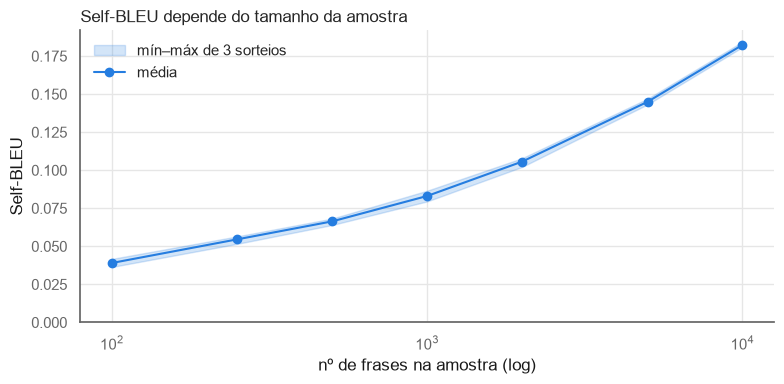

,mean,min,max
n,,,
100,0.039,0.036,0.042
250,0.055,0.052,0.057
500,0.066,0.064,0.068
1000,0.083,0.080,0.087
2000,0.106,0.102,0.108
5000,0.145,0.143,0.147
10000,0.182,0.181,0.184


In [35]:
tamanhos = [100, 250, 500, 1000, 2000, 5000, 10000]
resultados = pd.DataFrame([{"n": n, "semente": s, "self_bleu": self_bleu(prosa.sample(n, random_state=s)["tokens"].tolist()).mean()}
                           for n in tamanhos for s in range(3)])
resumo_sb = resultados.groupby("n")["self_bleu"].agg(["mean", "min", "max"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(resumo_sb.index, resumo_sb["min"], resumo_sb["max"], color=AZUL, alpha=0.2, label="mín–máx de 3 sorteios")
ax.plot(resumo_sb.index, resumo_sb["mean"], "o-", color=AZUL, label="média")
ax.set(xscale="log", xlabel="nº de frases na amostra (log)", ylabel="Self-BLEU", ylim=(0, None))
ax.set_title("Self-BLEU depende do tamanho da amostra", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
resumo_sb.round(3)

- O Self-BLEU não para de subir: 0,039 com 100 frases, 0,106 com 2.000 e 0,182 com 10.000. As frases são do mesmo corpus; a única coisa que mudou foi quantas eu comparei.
- A faixa dos sorteios é estreita, então, para um tamanho fixo, o valor é estável. O problema é comparar tamanhos diferentes.
- Por isso o Self-BLEU só serve para comparar conjuntos com o **mesmo número de textos** e, como os splits mostraram, de origem parecida. Um "Self-BLEU = 0,1" sozinho não diz nada se eu não souber o tamanho da amostra.

**Limitações do Self-BLEU:**
- Depende do tamanho da amostra (gráfico acima) e de quantos textos diferentes ela mistura (comparação entre splits).
- Mede a repetição da **forma** (n-gramas), não do significado. Duas frases com o mesmo sentido escritas com palavras diferentes têm Self-BLEU baixo: no exemplo dos embeddings, `cat`/`kitten` tem só 0,20 de palavras em comum, mas cosseno de 0,63.
- Foi criado para texto gerado por modelos. Em texto escrito por pessoas, os valores são baixos e ficam muito sensíveis a frases feitas e duplicatas.
- O custo cresce com o número de textos. A implementação com a maior e a segunda maior contagem evita comparar cada par um por um.

## Diversidade temática

Na diversidade semântica eu medi o quanto os textos são diferentes entre si. Na temática, a pergunta é **de quais assuntos** o corpus fala: quantos são, quanto espaço cada um ocupa e se estão equilibrados. Para responder isso, primeiro preciso agrupar os artigos em tópicos.

### Número de tópicos

**Definição:** aqui, um tópico é um grupo de artigos sobre o mesmo assunto. Para formar os grupos, apliquei o **K-means** 

In [54]:
from nltk.corpus import stopwords
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

STOP = set(stopwords.words("english"))

def entropia(contagens):
    p = np.asarray(contagens, dtype=float)
    p = p[p > 0] / p.sum()
    return -(p * np.log2(p)).sum()                     # em bits

ks = list(range(4, 300, 1))
modelos = {k: KMeans(n_clusters=k, n_init=10, random_state=0).fit(V) for k in ks}
escolha = pd.DataFrame({
    "k": ks,
    "silhueta": [silhouette_score(V, modelos[k].labels_, metric="cosine") for k in ks],
    "entropia_norm": [entropia(np.bincount(modelos[k].labels_)) / np.log2(k) for k in ks],
})
K = int(escolha.loc[escolha["silhueta"].idxmax(), "k"])
print(f"K escolhido: {K} (silhueta {escolha['silhueta'].max():.3f})")
escolha.set_index("k").round(3).T            # k vira o cabeçalho e fica inteiro

K escolhido: 14 (silhueta 0.181)


k,4,5,6,7,8,9,10,11,12,13,...,290,291,292,293,294,295,296,297,298,299
silhueta,0.105,0.126,0.130,0.144,0.154,0.161,0.164,0.171,0.174,0.164,...,0.132,0.126,0.123,0.128,0.132,0.126,0.131,0.126,0.119,0.123
entropia_norm,0.935,0.951,0.958,0.965,0.962,0.974,0.981,0.984,0.981,0.986,...,0.953,0.951,0.958,0.956,0.951,0.953,0.952,0.956,0.960,0.959


**Gráfico 2.6** · Quantos tópicos?

Para usar o K-means eu precisava escolher o K, e o valor escolhido já responde a uma das perguntas da atividade (o número de tópicos). Também quis ver se a entropia, que mede o equilíbrio entre os tópicos, muda muito conforme o K.

- na esquerda está a silhueta média para cada K testado, com o K escolhido marcado pela linha tracejada. Na direita, a entropia normalizada da distribuição de artigos por tópico para cada K (1 = todos os tópicos com o mesmo tamanho).

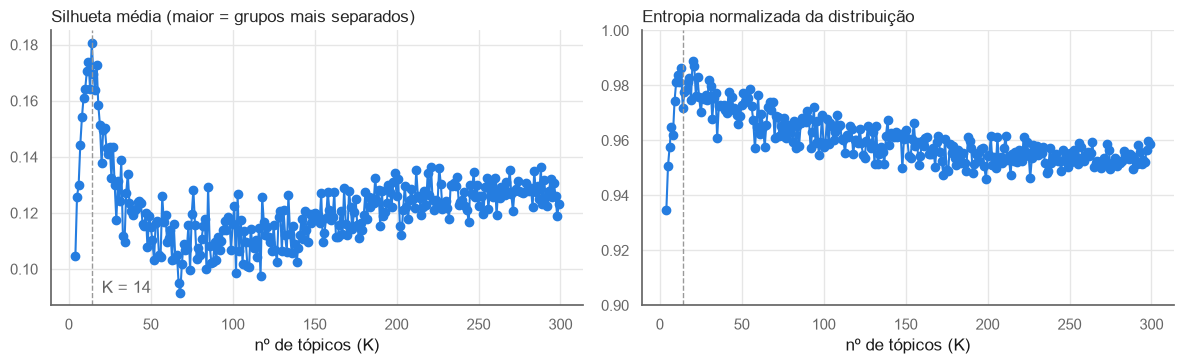

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, titulo in [(axes[0], "silhueta", "Silhueta média (maior = grupos mais separados)"),
                        (axes[1], "entropia_norm", "Entropia normalizada da distribuição")]:
    ax.plot(escolha["k"], escolha[col], "o-", color=AZUL)
    ax.axvline(K, color="#999999", linestyle="--", linewidth=1)
    ax.set(xlabel="nº de tópicos (K)")
    ax.set_title(titulo, loc="left")
axes[0].text(K, escolha["silhueta"].min(), f"  K = {K}", color="#666666")
axes[1].set_ylim(0.9, 1.0)
plt.tight_layout()
plt.show()

- A silhueta é máxima em **K = 14** (0,18) e cai dos dois lados: com poucos tópicos, assuntos diferentes acabam juntos; com muitos, um mesmo assunto é quebrado em pedaços.
- Mesmo assim, 0,18 é uma silhueta **baixa** (grupos bem separados costumam passar de 0,5). Os tópicos existem, mas se encostam: muitos artigos estão quase tão perto do grupo vizinho quanto do próprio. O WikiText-2 não tem "caixas" de assunto bem definidas, e sim um contínuo com algumas regiões mais densas.
- A entropia normalizada fica entre 0,93 e 0,99 para qualquer K, então a distribuição é sempre quase equilibrada. Parte disso vem do próprio K-means, que tende a formar grupos de tamanhos parecidos (volto a isso nas limitações).
- Por isso, encaro os 14 tópicos como uma escolha razoável para este método e este critério, e não como o número "verdadeiro" de assuntos do dataset.

### Distribuição dos assuntos

Com o K definido, cada artigo recebe um tópico. Só que o K-means devolve apenas números (tópico 0, 1, 2...), então precisei de outra forma de descrever cada grupo:
- **palavras-chave:** as palavras que aparecem em muitos artigos do tópico e em poucos artigos fora dele. É a ideia do c-TF-IDF do BERTopic (Grootendorst, 2022), mas contando artigos em vez de ocorrências, para que o nome de uma pessoa repetido num único artigo não vire palavra-chave do grupo inteiro:

$$\text{peso}(t, c) = \underbrace{\frac{\text{artigos do tópico } c \text{ com a palavra } t}{\text{artigos do tópico } c}}_{\text{comum dentro do tópico}} \times \underbrace{\log \frac{\text{total de artigos}}{\text{artigos com } t}}_{\text{rara no corpus}}$$

- **exemplos:** os 3 artigos mais próximos do centro do grupo, ou seja, os mais "típicos" do tópico.

Deixei de fora das palavras-chave as stopwords, os números e as palavras com até 2 letras.

In [38]:
km = modelos[K]
artigos["topico"] = km.labels_
centros = km.cluster_centers_ / np.linalg.norm(km.cluster_centers_, axis=1, keepdims=True)
artigos["sim_centro"] = np.einsum("ij,ij->i", V, centros[artigos["topico"]])   # quão típico do tópico

conjuntos = artigos["tokens"].map(lambda ts: {t for t in ts if t.isalpha() and len(t) > 2 and t not in STOP})
n_artigos_com = Counter(t for s in conjuntos for t in s)

def palavras_chave(topico, n=8):
    membros = conjuntos[artigos["topico"] == topico]
    dentro = Counter(t for s in membros for t in s)
    peso = {t: k / len(membros) * np.log(len(artigos) / n_artigos_com[t]) for t, k in dentro.items()}
    return sorted(peso, key=peso.get, reverse=True)[:n]

topicos = pd.DataFrame({"topico": range(K)})
topicos["palavras_chave"] = topicos["topico"].map(palavras_chave)
topicos["exemplos"] = topicos["topico"].map(
    lambda t: artigos[artigos["topico"] == t].nlargest(3, "sim_centro")["artigo"].tolist())
contagem = pd.crosstab(artigos["topico"], artigos["split"]).reindex(columns=list(CORES), fill_value=0)
topicos = topicos.join(contagem, on="topico")
topicos["artigos"] = contagem.sum(axis=1).to_numpy()
topicos["rotulo"] = topicos["palavras_chave"].map(lambda p: " · ".join(p[:3]))
topicos = topicos.sort_values("artigos", ascending=False).reset_index(drop=True)

with pd.option_context("display.max_colwidth", 120):
    display(topicos[["topico", "artigos", "train", "validation", "test", "palavras_chave", "exemplos"]])

,topico,artigos,train,validation,test,palavras_chave,exemplos
0,4,84,64,8,12,"[navy, guns, naval, command, commander, gun, officers, troops]","[St Nazaire Raid, Gold Beach, SMS Markgraf]"
1,7,80,64,10,6,"[episodes, episode, viewers, aired, television, ratings, guest, broadcast]","[... Thirteen Years Later, Training Day (The Office), Horrible Bosses]"
2,2,76,66,6,4,"[album, billboard, vocals, chart, songs, lyrics, song, recording]","[Where the Streets Have No Name, Charmbracelet, Loose (Nelly Furtado album)]"
3,6,75,61,6,8,"[championship, win, scored, victory, teams, league, coach, games]","[2013 – 14 York City F.C. season, History of Bradford City A.F.C., Stuart McCall]"
4,13,72,60,5,7,"[readers, books, publication, literary, describes, book, sense, published]","[Hugh Walpole, Imagism, The Portage to San Cristobal of A.H.]"
5,12,49,43,4,2,"[temple, dynasty, ruler, temples, muslim, son, religious, ruled]","[Magadheera, Varanasi, Pokiri]"
6,11,42,38,2,2,"[genus, species, specimens, epithet, closely, habitats, genera, distinct]","[Astraeus hygrometricus, Mycena galericulata, Mycena inclinata]"
7,9,39,33,1,5,"[appointed, king, elected, heir, court, earl, brother, ecclesiastical]","[Henry of Grosmont, 1st Duke of Lancaster, Osbert de Bayeux, Simon de Montfort's Parliament]"
8,1,39,31,6,2,"[highway, intersection, terminus, highways, roadway, traffic, interchange, intersects]","[U.S. Route 2 in Michigan, M-5 (Michigan highway), Rhode Island Route 4]"
9,3,36,33,1,2,"[gameplay, gaming, graphics, playstation, player, games, nintendo, ign]","[The Secret of Monkey Island, Tales of Destiny 2, Crash Boom Bang!]"


**Gráfico 2.7** · Quais são os assuntos e como estão distribuídos?

Este gráfico responde diretamente às perguntas 1, 2 e 5 da Etapa 3 (quais são os assuntos mais frequentes, como estão distribuídos e quais são pouco representados) e também mostra se os três splits cobrem os mesmos assuntos.

- cada barra é um tópico, identificado pelas suas 3 primeiras palavras-chave, e o comprimento é o nº de artigos, dividido por split. A linha tracejada marca quantos artigos cada tópico teria se a distribuição fosse uniforme (720 / 14 ≈ 51).

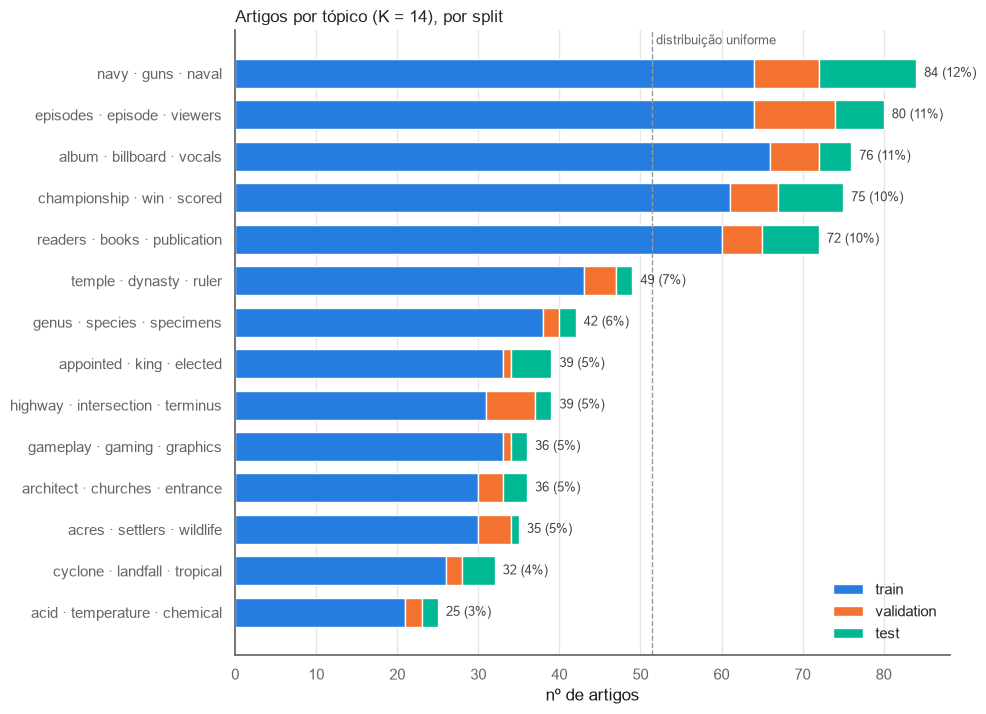

In [39]:
fig, ax = plt.subplots(figsize=(10, 0.45 * K + 1))
ordem = topicos[::-1]
esquerda = np.zeros(len(ordem))
for split, cor in CORES.items():
    ax.barh(ordem["rotulo"], ordem[split], left=esquerda, color=cor, label=split, height=0.7)
    esquerda += ordem[split].to_numpy()
for y, total in enumerate(ordem["artigos"]):
    ax.text(total + 1, y, f"{total} ({total / len(artigos):.0%})", va="center", fontsize=9, color="#444444")
ax.axvline(len(artigos) / K, color="#999999", linestyle="--", linewidth=1)
ax.text(len(artigos) / K, len(ordem) - 0.3, " distribuição uniforme", color="#666666", fontsize=9)
ax.set(xlabel="nº de artigos")
ax.set_title(f"Artigos por tópico (K = {K}), por split", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

Lendo as palavras-chave e os exemplos da tabela acima, identifiquei os 14 tópicos assim:

| Palavras-chave | Artigos | Assunto (exemplos mais típicos) |
|---|---|---|
| navy · guns · naval | 84 (12%) | história militar (`St Nazaire Raid`, `Gold Beach`, `SMS Markgraf`) |
| episodes · episode · viewers | 80 (11%) | episódios de séries e filmes (`Training Day (The Office)`, `Horrible Bosses`) |
| album · billboard · vocals | 76 (11%) | música, álbuns e canções (`Where the Streets Have No Name`) |
| championship · win · scored | 75 (10%) | esportes, principalmente futebol (`History of Bradford City A.F.C.`) |
| readers · books · publication | 72 (10%) | literatura e escritores (`Hugh Walpole`, `Imagism`) |
| temple · dynasty · ruler | 49 (7%) | Índia e sul da Ásia: história, religião, cidades e cinema (`Varanasi`, `Magadheera`) |
| genus · species · specimens | 42 (6%) | biologia, muitas espécies de fungos (`Mycena galericulata`) |
| appointed · king · elected | 39 (5%) | nobreza, clero e política medieval (`Simon de Montfort's Parliament`) |
| highway · intersection · terminus | 39 (5%) | estradas dos EUA (`M-5 (Michigan highway)`) |
| gameplay · gaming · graphics | 36 (5%) | videogames (`The Secret of Monkey Island`) |
| architect · churches · entrance | 36 (5%) | arquitetura e igrejas (`St Mary's Church, Nether Alderley`) |
| acres · settlers · wildlife | 35 (5%) | geografia e natureza: rios, montanhas, parques (`Adams River`) |
| cyclone · landfall · tropical | 32 (4%) | furacões e tempestades (`1955 Atlantic hurricane season`) |
| acid · temperature · chemical | 25 (3%) | ciências exatas: química, física, astronomia (`Europium`, `Xenon`, `WASP-13b`) |

- **Mais frequentes:** história militar, TV e cinema, música, esportes e literatura somam **54%** do corpus.
- **Pouco representados:** o menor tópico é o de ciências exatas (3%), e ele ainda junta química, física e astronomia. Medicina, economia, tecnologia, filosofia e política atual nem chegam a formar tópico próprio.
- **Furacões (32 artigos) e estradas (39) têm mais artigos que todas as ciências exatas juntas (25).** Isso tem a ver com a origem do dataset: o WikiText foi montado só com artigos marcados como *Good* e *Featured* na Wikipédia (Merity et al., 2017), e alguns grupos de editores produzem muitos artigos desse nível (história militar, furacões, estradas). Então a distribuição mostra o que a comunidade da Wikipédia escreveu com qualidade, e não a importância de cada assunto no mundo.
- **Splits:** os 14 tópicos aparecem nos três splits, mas em proporções diferentes. No test, história militar tem 12 dos 60 artigos (20%), enquanto videogames tem só 1 artigo no validation e 2 no test, e geografia tem 1 no test. Com 60 artigos, um tópico de 5% tem em média 3 artigos, o que deixa qualquer avaliação "por tema" no test muito frágil.

### Entropia temática

**Definição:** a entropia de Shannon (1948) mede o quanto uma distribuição está espalhada. Sendo $p_k$ a fração dos artigos no tópico *k*:

$$H = -\sum_{k=1}^{K} p_k \log_2 p_k \qquad\qquad H_{\text{norm}} = \frac{H}{\log_2 K}$$

O H é medido em bits e vai de 0 (todos os artigos num tópico só) até $\log_2 K$ (todos os tópicos com o mesmo número de artigos). Dividindo pelo máximo, o $H_{\text{norm}}$ fica entre 0 e 1, o que permite comparar distribuições com números de tópicos diferentes.

Um exemplo com 4 tópicos: (25%, 25%, 25%, 25%) dá H = 2 bits e $H_{\text{norm}}$ = 1; (70%, 10%, 10%, 10%) dá H ≈ 1,36 bits e $H_{\text{norm}}$ ≈ 0,68; e (100%, 0, 0, 0) dá 0.

Calculei a entropia para o corpus inteiro e para cada split, sempre com os mesmos K tópicos.

In [40]:
print("exemplos:", [round(entropia(p), 2) for p in ([25, 25, 25, 25], [70, 10, 10, 10], [100])])

linhas = []
for nome, parte in [("corpus", artigos)] + [(s, artigos[artigos["split"] == s]) for s in CORES]:
    c = np.bincount(parte["topico"], minlength=K)
    linhas.append({"conjunto": nome, "artigos": len(parte), "H (bits)": entropia(c), "H máx": np.log2(K),
                   "H norm": entropia(c) / np.log2(K), "tópicos ausentes": int((c == 0).sum()),
                   "maior tópico": f"{c.max() / c.sum():.0%}"})
pd.DataFrame(linhas).set_index("conjunto").round(3)

exemplos: [np.float64(2.0), np.float64(1.36), np.float64(-0.0)]


,artigos,H (bits),H máx,H norm,tópicos ausentes,maior tópico
conjunto,,,,,,
corpus,720,3.699,3.807,0.972,0,12%
train,600,3.710,3.807,0.974,0,11%
validation,60,3.538,3.807,0.929,0,17%
test,60,3.498,3.807,0.919,0,20%


**Interpretação:**
- No corpus, H = 3,70 bits de um máximo de 3,81 (log₂ 14), o que dá uma **entropia normalizada de 0,97**: os assuntos estão quase igualmente distribuídos, e o maior tópico tem só 12% dos artigos.
- No validation e no test a entropia é um pouco menor (0,93 e 0,92), e o maior tópico chega a 17% e 20%. Com só 60 artigos espalhados em 14 tópicos, é normal que a distribuição fique mais desigual por acaso. Nenhum tópico ficou de fora.
- Ou seja, considerando os tópicos que o próprio dataset forma, o WikiText-2 é tematicamente equilibrado.

**Limitações:**
- O número de tópicos depende do método e do critério. Outro algoritmo (LDA, BERTopic) ou outro critério (coerência de tópicos em vez de silhueta) levaria a outro K e a outros grupos. A silhueta baixa (0,18) já mostra que as fronteiras entre os tópicos são fracas.
- O K-means tende a formar grupos de tamanhos parecidos, então parte da entropia alta vem do próprio método. A entropia também muda com o K (Gráfico 2.6).
- Os tópicos são formados a partir dos próprios artigos do corpus. Por isso a entropia mede o equilíbrio **entre os assuntos que existem no dataset**, e não a cobertura dos assuntos do mundo. Uma distribuição equilibrada entre 14 tópicos que deixam de fora medicina, economia e tecnologia não é uma boa cobertura temática (pergunta da Etapa 4).
- Cada artigo recebe um tópico só, mas muitos misturam assuntos. Às vezes o agrupamento junta por região em vez de gênero: os filmes indianos (`Magadheera`, `Pokiri`) foram para o tópico "Índia", e não para o de filmes.
- Os nomes dos tópicos são uma interpretação minha, feita a partir das palavras-chave e dos exemplos.

### Resumo da diversidade temática

- O K-means sobre os embeddings encontra **14 tópicos**, com fronteiras fracas (silhueta de 0,18).
- A distribuição é **equilibrada** (entropia normalizada de 0,97), e história militar, TV, música, esportes e literatura somam metade do corpus.
- **Ciências exatas são o assunto menos representado** (3%), e vários assuntos nem aparecem. O perfil temático reflete quais artigos a Wikipédia marca como *Good* e *Featured*.
- Todos os tópicos aparecem nos três splits, mas validation e test têm poucos artigos por tópico.

## Redundância

Redundância é texto que aparece mais de uma vez, igual ou quase igual. Em dados de treino de modelos de linguagem, isso importa por dois motivos: o modelo vê o mesmo trecho várias vezes e tende a decorá-lo, e, se um trecho do test também está no train, a avaliação fica otimista demais (Lee et al., 2022). Procurei redundância em três níveis, do mais rígido ao mais solto:

1. **duplicatas exatas:** o mesmo parágrafo ou frase, palavra por palavra;
2. **quase duplicatas:** parágrafos que compartilham a maior parte das sequências de palavras (Jaccard);
3. **semelhança semântica:** trechos que dizem quase a mesma coisa, mesmo com outras palavras (embeddings).

### Duplicatas exatas

**Definição:** dois textos são duplicatas exatas quando ficam iguais depois de normalizados (em minúsculas e só com as palavras, sem pontuação). Contei os parágrafos (cada linha do dataset) e as frases (da tabela `prosa`) com **pelo menos 8 palavras**. Itens curtos como `Personal life` ou `Track listing` se repetem naturalmente e não representam redundância de conteúdo, então deixei de fora.

In [41]:
secoes = pd.read_parquet(DATA_DIR / "secoes.parquet")
pars = (secoes.assign(paragrafo=secoes["text_limpo"].str.split("\n"))
        .explode("paragrafo").drop(columns="text_limpo").reset_index(drop=True))
pars["norm"] = pars["paragrafo"].str.lower().str.findall(PALAVRA).str.join(" ")
pars["n_palavras"] = pars["norm"].str.split().str.len()

MIN_PAL = 8
longos = pars[pars["n_palavras"] >= MIN_PAL]
prosa["norm"] = prosa["tokens"].str.join(" ")
frases_longas = prosa[prosa["tokens"].str.len() >= MIN_PAL]

def resumo_duplicatas(tabela, coluna_texto):
    dup = tabela[tabela.duplicated("norm", keep=False)]
    grupos = dup.groupby("norm").agg(vezes=("artigo", "size"), artigos=("artigo", "nunique"),
                                     splits=("split", lambda s: ", ".join(sorted(set(map(str, s))))),
                                     exemplo=(coluna_texto, "first"))
    print(f"{len(tabela):,} textos · {len(dup):,} fazem parte de duplicatas ({len(dup) / len(tabela):.2%}) · "
          f"{len(grupos)} textos diferentes repetidos · {(grupos['splits'].str.contains(',')).sum()} aparecem em mais de um split")
    return grupos.sort_values("vezes", ascending=False).reset_index(drop=True)

print("PARÁGRAFOS")
dup_pars = resumo_duplicatas(longos, "paragrafo")
print("FRASES")
dup_frases = resumo_duplicatas(frases_longas, "frase")
with pd.option_context("display.max_colwidth", 110):
    display(dup_pars.head(8)[["vezes", "artigos", "splits", "exemplo"]],
            dup_frases.head(8)[["vezes", "artigos", "splits", "exemplo"]])

PARÁGRAFOS
19,736 textos · 16 fazem parte de duplicatas (0.08%) · 7 textos diferentes repetidos · 0 aparecem em mais de um split
FRASES
88,312 textos · 284 fazem parte de duplicatas (0.32%) · 138 textos diferentes repetidos · 18 aparecem em mais de um split


,vezes,artigos,splits,exemplo
0,4,2,train,Note: Flags indicate national team as defined under FIFA eligibility rules. Players may hold more than one...
1,2,1,train,Credits adapted from the liner notes of The Family Jewels.
2,2,2,train,Credits adapted from the liner notes for Fortune
3,2,1,test,Feud of the Year (2003) vs. Kurt Angle
4,2,2,train,Note: Only the top five positions are included for both sets of standings.
5,2,1,train,Sourced from Tommy Lawton profile at the English National Football Archive (subscription required)
6,2,1,train,Teams marked * progressed to the next stage of the competition.


,vezes,artigos,splits,exemplo
0,4,2,train,Players may hold more than one non-FIFA nationality.
1,4,2,train,Note: Flags indicate national team as defined under FIFA eligibility rules.
2,3,3,train,"Set in the 22nd century, the series follows the adventures of the first Starfleet starship Enterprise, reg..."
3,3,1,train,She was one of the U.S. destroyers sent out to rescue survivors from five victims of German submarine U-53...
4,3,3,"train, validation",The Boat Race is a side-by-side rowing competition between the University of Oxford (sometimes referred to...
5,3,3,"test, train",The series depicts the adventures of Veronica Mars (Kristen Bell) as she deals with life as a college stud...
6,2,2,train,"ACE is, broadly speaking, a measure of the power of the hurricane multiplied by the length of time it exis..."
7,2,1,test,"After the London Paralympics, Dodd took up wheelchair basketball."


- **Parágrafos:** só 16 dos 19.736 parágrafos com 8 palavras ou mais (0,08%) se repetem, formando 7 textos diferentes, todos dentro do mesmo split. São notas de tabela e créditos, como "Note: Flags indicate national team as defined under FIFA eligibility rules..." (4 vezes, em 2 artigos), "Credits adapted from the liner notes of..." e "Note: Only the top five positions are included...".
- **Frases:** 284 de 88.312 (0,32%) fazem parte de duplicatas (138 frases diferentes), e 18 delas aparecem em mais de um split. São principalmente **frases de molde**, repetidas em artigos da mesma série: a descrição de Star Trek: Enterprise ("Set in the 22nd century, the series follows...") em 3 episódios, a descrição do Boat Race (train e validation) e a de Veronica Mars (train e test).
- Ou seja, a duplicação exata é quase inexistente, e o pouco que existe é texto padrão de tabela ou de série, e não artigos copiados.

### Quase duplicatas (Jaccard)

**Definição:** transformo cada parágrafo no conjunto das suas sequências de 5 palavras seguidas (*shingles*) e comparo dois parágrafos pela **similaridade de Jaccard** (Broder, 1997):

$$J(A, B) = \frac{|A \cap B|}{|A \cup B|}$$

Ela é a fração das sequências que os dois têm em comum: 1 quer dizer que os conjuntos são iguais, e 0, que não têm nada em comum. Como sequências de 5 palavras raramente se repetem por acaso, um J alto indica texto copiado ou adaptado. Tratei como quase duplicata todo par com **J ≥ 0,5**.

Comparar 20 mil parágrafos dois a dois dá 200 milhões de pares. Para não fazer isso um por um, montei uma matriz parágrafo × shingle (com 1 quando o parágrafo tem aquele shingle). O produto dessa matriz pela sua transposta dá, de uma vez só, quantos shingles cada par tem em comum. Deixei de fora os shingles que aparecem em mais de 20 parágrafos, como `one of the most` ou `at the end of the`, porque são expressões comuns e não indicam cópia. Em corpora muito maiores, o normal é usar o **MinHash**, uma aproximação do Jaccard proposta no mesmo artigo do Broder. Aqui o cálculo exato coube na memória.

In [42]:
from sklearn.feature_extraction.text import CountVectorizer

def shingles(texto, n=5):
    w = texto.split()
    return [" ".join(w[i:i + n]) for i in range(len(w) - n + 1)]

unicos = longos.drop_duplicates("norm").reset_index(drop=True)   # duplicatas exatas já foram contadas
X = CountVectorizer(analyzer=shingles, binary=True).fit_transform(unicos["norm"])
em_quantos = np.asarray(X.sum(axis=0)).ravel()
X = X[:, em_quantos <= 20].tocsr()                                # tira expressões comuns
tam = np.asarray(X.sum(axis=1)).ravel()

comum = (X @ X.T).tocoo()                                         # shingles em comum entre cada par
m = comum.row < comum.col
i, j, inter = comum.row[m], comum.col[m], comum.data[m]
jac = inter / (tam[i] + tam[j] - inter)

quase = pd.DataFrame({"i": i, "j": j, "jaccard": jac}).query("jaccard >= 0.5")
for lado in "ij":
    quase[f"artigo_{lado}"] = unicos.loc[quase[lado], "artigo"].to_numpy()
    quase[f"split_{lado}"] = unicos.loc[quase[lado], "split"].astype(str).to_numpy()
    quase[f"texto_{lado}"] = unicos.loc[quase[lado], "paragrafo"].str[:90].to_numpy()
mesmo_artigo = (quase["artigo_i"] == quase["artigo_j"])
outro_split = (quase["split_i"] != quase["split_j"])
print(f"{len(unicos):,} parágrafos · {X.shape[1]:,} shingles · {len(quase)} pares com J ≥ 0,5 "
      f"({mesmo_artigo.sum()} no mesmo artigo, {(~mesmo_artigo).sum()} em artigos diferentes, {outro_split.sum()} entre splits)")
with pd.option_context("display.max_colwidth", 90):
    display(quase.sort_values("jaccard", ascending=False)
            [["jaccard", "artigo_i", "split_i", "artigo_j", "split_j", "texto_i", "texto_j"]].head(10).round(2))

19,727 parágrafos · 1,940,617 shingles · 27 pares com J ≥ 0,5 (22 no mesmo artigo, 5 em artigos diferentes, 2 entre splits)


,jaccard,artigo_i,split_i,artigo_j,split_j,texto_i,texto_j
29913,0.90,The Boat Race 1999,train,The Boat Race 2008,validation,"The first Women's Boat Race took place in 1927, but did not become an annual fixture u...","The first Women's Boat Race took place in 1927, but did not become an annual fixture u..."
39535,0.88,Georgian scripts,train,Georgian scripts,train,"Ingush language (historically), later replaced in the 17th century by Arabic and by th...","Avar language (historically), later replaced in the 17th century by Arabic and by the ..."
39537,0.88,Georgian scripts,train,Georgian scripts,train,"Chechen language (historically), later replaced in the 17th century by Arabic and by t...","Avar language (historically), later replaced in the 17th century by Arabic and by the ..."
39536,0.88,Georgian scripts,train,Georgian scripts,train,"Ingush language (historically), later replaced in the 17th century by Arabic and by th...","Chechen language (historically), later replaced in the 17th century by Arabic and by t..."
29251,0.74,O'Brien-class destroyer,train,O'Brien-class destroyer,train,"After Winslow's August 1915 commissioning, she sailed off the east coast and in the Ca...","After Cushing's August 1915 commissioning, she sailed off the east coast and in the Ca..."
29202,0.70,O'Brien-class destroyer,train,USS O'Brien (DD-51),train,"After returning to the United States in January 1919, O'Brien returned to European wat...","After returning to the United States in January 1919, O'Brien revisited European water..."
29187,0.68,O'Brien-class destroyer,train,USS O'Brien (DD-51),train,"After O'Brien's May 1915 commissioning, she sailed off the east coast and in the Carib...","After her May 1915 commissioning, O'Brien sailed off the east coast and in the Caribbe..."
32116,0.67,Gregory Helms,train,Gregory Helms,train,NDW Tag Team Championship (1 time) – with Mike Maverick,SCW Tag Team Championship (1 time) – with Mike Maverick
19746,0.64,Somerset County Cricket Club in 2009,train,Somerset County Cricket Club in 2009,train,Somerset deducted 1 point for a slow over-rate in their match against Durham.,Sussex deducted 1 point for a slow over-rate in their match against Worcestershire.Notes:
19744,0.64,Somerset County Cricket Club in 2009,train,Somerset County Cricket Club in 2009,train,Durham deducted 1 point for a slow over-rate in their match against Sussex.,Sussex deducted 1 point for a slow over-rate in their match against Worcestershire.Notes:


- Só **27 pares** de parágrafos têm J ≥ 0,5. Desses, 22 estão no mesmo artigo e são listas com a mesma estrutura: `Georgian scripts` repete "X language (historically), later replaced in the 17th century by Arabic..." trocando só o nome da língua, e `Somerset County Cricket Club in 2009` repete as notas de pontos descontados.
- Outros 5 pares estão em artigos diferentes e são textos adaptados de um artigo para o outro. Por exemplo, `O'Brien-class destroyer` (a classe de navios) e `USS O'Brien (DD-51)` (um navio da classe) têm parágrafos quase iguais sobre o comissionamento.
- 2 pares atravessam splits. O principal é do Boat Race: `The Boat Race 1999` (train) e `The Boat Race 2008` (validation) têm um parágrafo sobre a corrida feminina com J = 0,90.
- Então as quase duplicatas também são raras e vêm de artigos escritos a partir de um modelo comum.

### Semelhança semântica

**Definição:** dois trechos são semanticamente redundantes quando dizem quase a mesma coisa, mesmo com palavras diferentes. Para encontrar esses casos, reaproveitei os embeddings dos blocos de 150 palavras da parte de diversidade semântica: para cada bloco, procurei o **bloco mais parecido de outro artigo do train** (o vizinho mais próximo) e anotei o cosseno.

Fiz isso tanto para os blocos do train (comparando com os outros artigos do train) quanto para os de validation e test (comparando com o train). Se os blocos de validation e test tivessem vizinhos no train muito mais próximos que os do próprio train, seria sinal de que o test repete conteúdo do treino. Tratei como redundância semântica um cosseno **≥ 0,9**.

**Gráfico 2.8** · O validation e o test repetem o conteúdo do train?

As duas formas anteriores só encontram texto com as mesmas palavras. Aqui eu quis saber se o conteúdo de validation e test já aparece no train, mesmo que reescrito, porque isso deixaria a avaliação de um modelo otimista.

- cada bloco de 150 palavras entra no histograma com a similaridade do bloco mais parecido que existe em **outro** artigo do train. Em azul estão os blocos do próprio train (a referência) e, em verde, os de validation e test. A linha em 0,9 marca o limite que usei para redundância semântica. A tabela abaixo mostra os blocos de validation/test mais próximos do train.

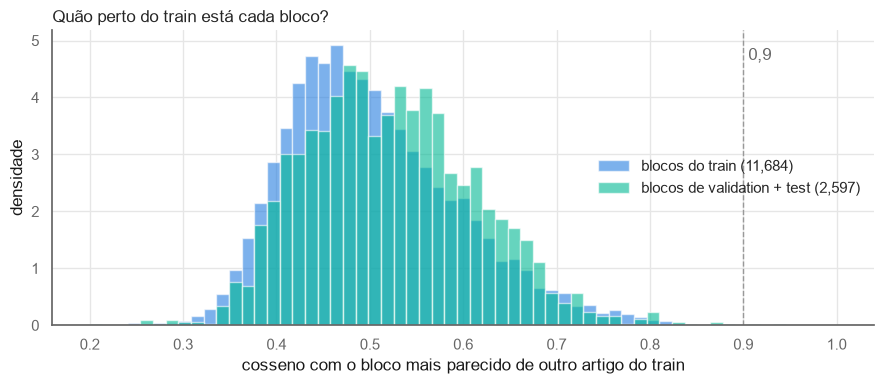

train              mediana 0.490 · ≥ 0,9: 2 blocos (0.0%) · ≥ 0,95: 0
validation + test  mediana 0.518 · ≥ 0,9: 2 blocos (0.1%) · ≥ 0,95: 0


In [43]:
art_bloco = blocos["art"].to_numpy()
eh_train = (artigos["split"].to_numpy()[art_bloco] == "train")
idx_train, idx_outros = np.where(eh_train)[0], np.where(~eh_train)[0]

def vizinho_no_train(origem, lote=2000):
    melhor, quem = np.empty(len(origem)), np.empty(len(origem), dtype=int)
    for ini in range(0, len(origem), lote):
        o = origem[ini:ini + lote]
        M = E[o] @ E[idx_train].T
        M[art_bloco[o][:, None] == art_bloco[idx_train][None, :]] = -1   # ignora blocos do mesmo artigo
        k = M.argmax(axis=1)
        melhor[ini:ini + lote], quem[ini:ini + lote] = M[np.arange(len(o)), k], idx_train[k]
    return melhor, quem

nn_train, viz_train = vizinho_no_train(idx_train)
nn_outros, viz_outros = vizinho_no_train(idx_outros)

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0.2, 1, 60)
ax.hist(nn_train, bins=bins, density=True, alpha=0.6, color=CORES["train"], label=f"blocos do train ({len(idx_train):,})")
ax.hist(nn_outros, bins=bins, density=True, alpha=0.6, color=CORES["test"], label=f"blocos de validation + test ({len(idx_outros):,})")
ax.axvline(0.9, color="#999999", linestyle="--", linewidth=1)
ax.text(0.9, ax.get_ylim()[1] * 0.9, " 0,9", color="#666666")
ax.set(xlabel="cosseno com o bloco mais parecido de outro artigo do train", ylabel="densidade")
ax.set_title("Quão perto do train está cada bloco?", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

for nome, nn in [("train", nn_train), ("validation + test", nn_outros)]:
    print(f"{nome:18s} mediana {np.median(nn):.3f} · ≥ 0,9: {(nn >= 0.9).sum()} blocos ({(nn >= 0.9).mean():.1%}) · ≥ 0,95: {(nn >= 0.95).sum()}")

In [44]:
top = np.argsort(nn_outros)[::-1][:6]
with pd.option_context("display.max_colwidth", 100):
    display(pd.DataFrame({
        "cosseno": nn_outros[top],
        "artigo (val/test)": artigos["artigo"].to_numpy()[art_bloco[idx_outros[top]]],
        "artigo (train)": artigos["artigo"].to_numpy()[art_bloco[viz_outros[top]]],
        "bloco val/test": blocos["texto"].to_numpy()[idx_outros[top]],
        "bloco train": blocos["texto"].to_numpy()[viz_outros[top]],
    }).assign(**{"bloco val/test": lambda d: d["bloco val/test"].str[:100],
                 "bloco train": lambda d: d["bloco train"].str[:100]}).round(3))

,cosseno,artigo (val/test),artigo (train),bloco val/test,bloco train
0,0.933,The Boat Race 2008,The Boat Race 1999,"The 154th Boat Race took place on 29 March 2008. Held annually, the event is a side-by-side rowi...","The 145th Boat Race took place on 3 April 1999. Held annually, the Boat Race is a side-by-side r..."
1,0.909,The Boat Race 2008,The Boat Race 1999,km) Championship Course on the River Thames in southwest London. The rivalry is a major point of...,and followed throughout the United Kingdom and broadcast worldwide. Cambridge went into the race...
2,0.881,2003 Pacific typhoon season,Typhoon Imbudo,"July 15, the JMA estimated that a tropical depression formed, and the next day the JTWC initiate...",passed about 35 km (20 mi) north of Yap. The JMA upgraded Imbudo to a severe tropical storm late...
3,0.874,2003 Pacific typhoon season,Typhoon Imbudo,"At 0300 UTC on July 22, Imbudo struck northern Luzon, with 1 minute winds estimated at 205 km / ...","a few days. On Mindanao, flash flooding from the outer periphery of the storm affected 18 towns,..."
4,0.869,The Boat Race 2008,The Boat Race 1999,"prevent a collision. By Craven Cottage, Oxford were nearly a length ahead and Cambridge responde...",lead was extended to a length by Hammersmith Bridge and Sharif had steered her boat into a bette...
5,0.850,Mycena inclinata,Mycena galericulata,"to yellow-brown, becoming reddish-brown to orange-brown in the bottom half in maturity. The lowe...",to black when stained with Melzer's reagent. The basidia (spore-bearing cells) have stout sterig...


- As duas distribuições são quase iguais: a mediana é de 0,49 no train e de 0,52 em validation + test. Um bloco típico tem no train algo do mesmo assunto (~0,5, o nível de "mesmo assunto" do Gráfico 2.3), mas não o mesmo conteúdo. Validation e test estão só um pouco mais perto do train do que o train está de si mesmo.
- Só **2 blocos** de validation/test passam de 0,9 (0,1%), e os dois são do `The Boat Race 2008` comparado com o `The Boat Race 1999`. Logo depois (de 0,85 a 0,88) vêm a temporada de tufões de 2003 comparada com o artigo de um tufão dessa temporada (`Typhoon Imbudo`, no train) e os dois cogumelos *Mycena*.
- Então **não há vazamento relevante** do train para o test: os casos são poucos e vêm de artigos feitos no mesmo molde, não de texto copiado.

**Limitações:**

- Duplicata nem sempre é um defeito: notas de tabela e descrições de série são repetições legítimas da Wikipédia.
- O Jaccard depende da tokenização e não enxerga paráfrase. O embedding enxerga paráfrase, mas o limite de 0,9 vale para este modelo (outro modelo teria outra escala).
- Os embeddings comparam blocos de 150 palavras, então um parágrafo copiado dentro de um bloco maior pode ficar diluído e não passar do limite.
- Só consegui comparar todos os pares porque o corpus é pequeno. Em corpos grandes, é preciso usar MinHash e busca aproximada de vizinhos.

### Resumo da redundância

O WikiText-2 tem **pouquíssima redundância**: 0,08% dos parágrafos e 0,32% das frases se repetem, há 27 pares de quase duplicatas e só 2 blocos de validation/test são semanticamente quase iguais a um bloco do train. O pouco que existe vem de artigos feitos no mesmo molde (Boat Race, navios da mesma classe, episódios da mesma série).

## Características textuais

Na Etapa 1 eu já tinha olhado o **comprimento** (palavras, frases e palavras por frase) e a **frequência de palavras** (palavras mais frequentes, lei de Zipf) do corpus inteiro. Aqui transformo essas características em medidas **por artigo** e acrescento medidas de **complexidade lexical**, para poder comparar artigos e, na Etapa 3, grupos de artigos.

### Medidas

| Medida | Definição | O que indica |
|---|---|---|
| `n_tokens` | nº de palavras do artigo | comprimento |
| `palavras_por_frase` | média de palavras por frase (só prosa, da Etapa 1) | complexidade sintática |
| `tam_palavra` | média de letras por palavra | palavras longas costumam ser mais técnicas |
| `densidade_lexical` | fração de palavras de conteúdo (não stopwords) | texto mais "informativo" e menos gramatical (Ure, 1971) |
| `pct_raras` | fração de palavras fora das 2.000 mais frequentes do corpus | vocabulário especializado (ideia do *Lexical Frequency Profile*, Laufer & Nation, 1995) |
| `flesch` | legibilidade de Flesch (1948) | facilidade de leitura |

O **índice de Flesch** combina o tamanho das frases com o tamanho das palavras (em sílabas):

$$\text{Flesch} = 206{,}835 - 1{,}015 \cdot \frac{\text{palavras}}{\text{frases}} - 84{,}6 \cdot \frac{\text{sílabas}}{\text{palavras}}$$

Quanto **maior** o valor, mais fácil é o texto: de 60 a 70 é texto comum, de 30 a 50 é texto de nível universitário e abaixo de 30 é muito difícil. Para contar as sílabas, usei uma regra simples: cada grupo de vogais seguidas (`a`, `e`, `i`, `o`, `u`, `y`) é uma sílaba, e um `e` mudo no fim não conta (`game` tem 1). Nas medidas por palavra, considerei só as palavras com letras (os números ficaram de fora).

In [45]:
import re

ALFA = re.compile(r"[a-z]+(?:[-'][a-z]+)*")
COMUNS = {w for w, _ in Counter(t for ts in artigos["tokens"] for t in ts).most_common(2000)}

def silabas(palavra):
    n = len(re.findall(r"[aeiouy]+", palavra))
    if palavra.endswith("e") and not palavra.endswith(("le", "ee")) and n > 1:
        n -= 1                                          # e mudo: game, make
    return max(1, n)

print({p: silabas(p) for p in ["cat", "game", "table", "reading", "beautiful", "the", "encyclopedia"]})

def caracteristicas(tokens):
    pal = [t for t in tokens if ALFA.fullmatch(t)]
    return {
        "tam_palavra": np.mean([len(p) for p in pal]),
        "densidade_lexical": np.mean([p not in STOP for p in pal]),
        "pct_raras": np.mean([p not in COMUNS for p in pal]),
        "silabas_por_palavra": np.mean([silabas(p) for p in pal]),
    }

feats = pd.DataFrame(artigos["tokens"].map(caracteristicas).tolist(), index=artigos.index)
artigos[feats.columns] = feats
artigos["flesch"] = 206.835 - 1.015 * artigos["palavras_por_frase"] - 84.6 * artigos["silabas_por_palavra"]

medidas = ["n_tokens", "palavras_por_frase", "tam_palavra", "densidade_lexical", "pct_raras", "flesch"]
artigos[medidas].describe().loc[["mean", "50%", "min", "max"]].round(3)

{'cat': 1, 'game': 1, 'table': 2, 'reading': 2, 'beautiful': 3, 'the': 1, 'encyclopedia': 5}


,n_tokens,palavras_por_frase,tam_palavra,densidade_lexical,pct_raras,flesch
mean,2882.242,22.466,4.958,0.578,0.273,43.401
50%,2043.500,22.263,4.938,0.578,0.273,43.888
min,226.000,13.904,4.421,0.487,0.156,-0.274
max,16088.000,37.000,6.015,0.686,0.436,66.242


**Gráfico 2.9** · Quão complexos são os textos?

Aqui eu quis ver o nível de complexidade dos artigos e se ele varia muito, porque um corpus inteiro num mesmo registro ensina o modelo a escrever só daquele jeito.

- cada histograma é uma medida: cada barra é uma faixa de valores, a altura é o nº de artigos nela e a linha marca a mediana. As tabelas abaixo mostram os 5 artigos mais difíceis e os 5 mais fáceis pelo Flesch.

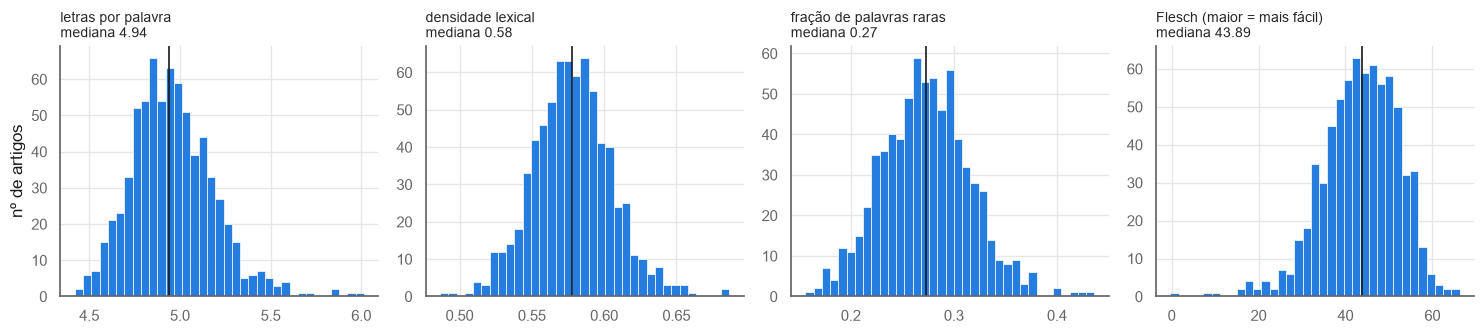

In [46]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, (col, nome) in zip(axes, [("tam_palavra", "letras por palavra"), ("densidade_lexical", "densidade lexical"),
                                  ("pct_raras", "fração de palavras raras"), ("flesch", "Flesch (maior = mais fácil)")]):
    ax.hist(artigos[col], bins=35, color=AZUL, edgecolor="white", linewidth=0.5)
    ax.axvline(artigos[col].median(), color="#191919", linewidth=1.2)
    ax.set_title(f"{nome}\nmediana {artigos[col].median():.2f}", loc="left", fontsize=10)
axes[0].set_ylabel("nº de artigos")
plt.tight_layout()
plt.show()

In [47]:
cols = ["split", "artigo", "palavras_por_frase", "tam_palavra", "pct_raras", "flesch"]
display(artigos.nsmallest(5, "flesch")[cols].round(3), artigos.nlargest(5, "flesch")[cols].round(3))

,split,artigo,palavras_por_frase,tam_palavra,pct_raras,flesch
684,test,Oxaziridine,19.308,6.015,0.417,-0.274
655,validation,Nazarov cyclization reaction,20.231,5.865,0.399,8.832
192,train,Ceratopsia,20.430,5.858,0.360,10.670
628,validation,Scientology in Germany,30.641,5.584,0.264,15.435
291,train,Sclerodermatineae,18.457,5.939,0.399,15.652


,split,artigo,palavras_por_frase,tam_palavra,pct_raras,flesch
181,train,"St Mary's Church, Nether Alderley",18.052,4.421,0.269,66.242
591,train,Midge (Barbie),18.153,4.587,0.292,65.662
644,validation,Thelnetham Windmill,16.962,4.642,0.273,63.605
497,train,Miss Meyers,18.263,4.469,0.272,63.469
178,train,M-114 (Michigan highway),20.407,4.593,0.196,61.353


- **Letras por palavra:** mediana de 4,9 (de 4,4 a 6,0). **Densidade lexical:** 58% das palavras são de conteúdo (de 49% a 69%). **Palavras raras:** 27% das palavras estão fora das 2.000 mais comuns do corpus.
- **Flesch:** mediana de 44, que é nível universitário (30 a 50). Quase todos os artigos ficam entre 30 e 60, ou seja, o corpus inteiro está num registro só, o de texto enciclopédico formal.
- Os mais difíceis são de química e biologia (`Oxaziridine`, com Flesch ≈ 0, `Nazarov cyclization reaction`, `Ceratopsia` e `Sclerodermatineae`), com palavras longas e técnicas (~6 letras em média e ~40% de palavras raras). `Scientology in Germany` aparece na lista por outro motivo: frases longas (31 palavras em média).
- Entre os mais fáceis (Flesch de 61 a 66) estão uma igreja, uma boneca (`Midge (Barbie)`), um moinho e uma estrada, com palavras curtas e comuns. Mesmo assim, o "mais fácil" só chega ao nível de texto comum.
- As medidas variam pouco de um artigo para outro (os histogramas são estreitos). Isso combina com o que vi nas outras partes: o WikiText-2 é diverso em assunto, mas homogêneo em estilo.

**Gráfico 2.10** · Panorama: quais medidas andam juntas?

Com todas as medidas por artigo calculadas, quis ver quais dizem a mesma coisa e quais trazem informação nova. Isso me ajuda a escolher o que usar na Etapa 3 e alimenta a discussão da Etapa 4.

- cada célula é a correlação de Spearman entre duas medidas nos 720 artigos (vermelho = andam juntas, azul = andam em sentidos opostos, branco = sem relação). A "tipicidade no tópico" é a similaridade do artigo com o centro do seu tópico.

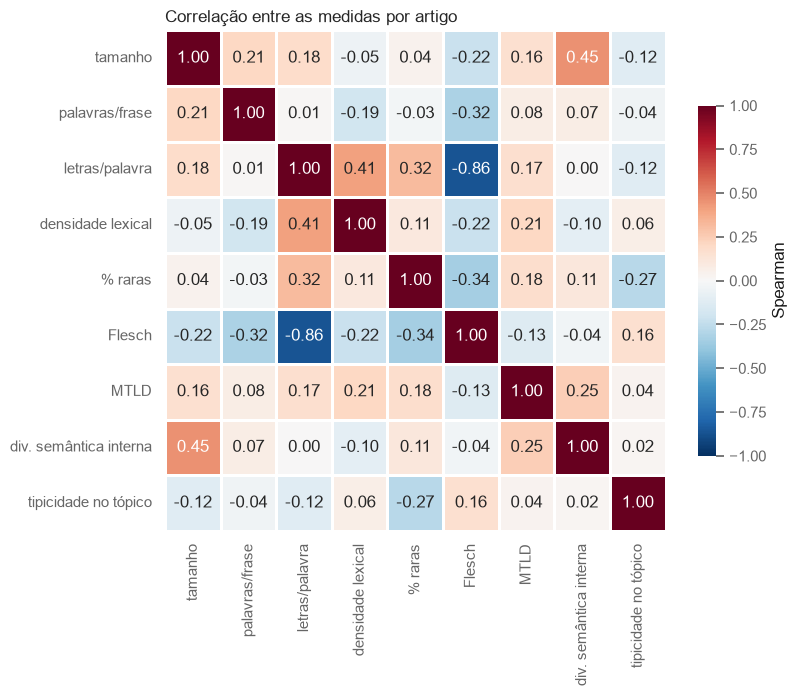

In [48]:
painel = {"n_tokens": "tamanho", "palavras_por_frase": "palavras/frase", "tam_palavra": "letras/palavra",
          "densidade_lexical": "densidade lexical", "pct_raras": "% raras", "flesch": "Flesch",
          "mtld": "MTLD", "div_semantica": "div. semântica interna", "sim_centro": "tipicidade no tópico"}
corr = artigos[list(painel)].rank().corr().rename(index=painel, columns=painel)

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            linewidths=1, linecolor="white", cbar_kws={"label": "Spearman", "shrink": 0.7}, ax=ax)
ax.set_title("Correlação entre as medidas por artigo", loc="left")
plt.tight_layout()
plt.show()

- **O Flesch é quase só tamanho de palavra:** a correlação é de −0,86 com letras por palavra e de só −0,32 com palavras por frase. Como o tamanho das frases varia pouco entre os artigos (Etapa 1), quem decide a legibilidade é o vocabulário.
- **Letras por palavra, densidade lexical e % de raras** se correlacionam entre si (de 0,32 a 0,41): todas medem, de jeitos diferentes, o quanto o vocabulário é técnico.
- **O MTLD quase não tem relação com a complexidade** (correlações entre 0,08 e 0,21, em módulo): um texto pode ser variado e fácil, ou repetitivo e técnico. Diversidade lexical e complexidade lexical são coisas diferentes.
- **A diversidade semântica interna só se relaciona com o tamanho** (0,45), como já tinha aparecido antes.
- **Os artigos menos típicos do seu tópico têm mais palavras raras** (−0,27): os artigos na borda de um grupo costumam ser de assuntos mais específicos, que não se encaixam bem em nenhum tópico.
- No geral, as correlações são baixas: cada família de medidas (tamanho, complexidade, diversidade lexical, diversidade semântica) traz informação própria, e nenhuma delas resume o dataset sozinha.

**Limitações:**
- A contagem de sílabas é uma regra aproximada: ela erra em palavras como `encyclopedia` (6 sílabas, mas a regra conta 5) e em nomes estrangeiros. Além disso, o Flesch foi calibrado com textos escolares em inglês dos anos 1940 e não diz nada sobre conteúdo nem coerência.
- A densidade lexical original (Ure, 1971) separa as palavras de conteúdo pela classe gramatical. Aqui usei a lista de stopwords como aproximação.
- "Palavra rara" foi definida pelo próprio corpus (fora das 2.000 mais frequentes do WikiText-2), e não por uma lista externa de frequência do inglês.
- O número de palavras por frase depende da divisão em frases feita pelo punkt e usa só a prosa.
- Todas são médias por artigo, então escondem variações internas (uma seção técnica dentro de um artigo fácil, por exemplo).

### Salvando para a Etapa 3

Salvo em `data/` a tabela com todas as medidas por artigo e a tabela de tópicos, para usar na Etapa 3 (visualizações) sem precisar recalcular tudo.

In [49]:
salvar = artigos.drop(columns=["tokens", "text_limpo"])
salvar.to_parquet(DATA_DIR / "metricas_artigos.parquet", index=False)
topicos.drop(columns=["exemplos"]).assign(palavras_chave=topicos["palavras_chave"].str.join(", "),
                                         exemplos=topicos["exemplos"].str.join(" | ")).to_parquet(DATA_DIR / "topicos.parquet", index=False)
np.save(DATA_DIR / "vetores_artigos.npy", V)
print(f"metricas_artigos.parquet: {salvar.shape} · topicos.parquet: {len(topicos)} tópicos · vetores_artigos.npy: {V.shape}")

metricas_artigos.parquet: (720, 24) · topicos.parquet: 14 tópicos · vetores_artigos.npy: (720, 384)


## Resumo da Etapa 2

| Grupo | Medida | Valor no WikiText-2 | O que diz |
|---|---|---|---|
| Diversidade lexical | MTLD | mediana de 85,5 palavras | vocabulário variado e parecido entre artigos e splits |
| | TTR | mediana 0,35, Spearman −0,82 com o tamanho | mede tamanho, não serve para comparar artigos |
| Diversidade semântica | 1 − cosseno médio entre artigos | 0,94 | os artigos falam de coisas muito diferentes |
| | Self-BLEU (2.000 frases) | 0,108 | pouca repetição de sequências, mas depende do tamanho da amostra |
| Diversidade temática | nº de tópicos (silhueta) | 14 (silhueta 0,18) | assuntos com fronteiras fracas |
| | entropia normalizada | 0,97 | distribuição equilibrada entre os assuntos que existem |
| Redundância | duplicatas exatas | 0,08% dos parágrafos, 0,32% das frases | quase nenhuma |
| | vizinho semântico ≥ 0,9 | 2 blocos de validation/test | sem vazamento relevante para o test |
| Características | Flesch | mediana de 44 | registro único, enciclopédico e formal |

**O que levo para a Etapa 4:**
- O WikiText-2 é **diverso em assunto** (diversidade semântica de 0,94, 14 tópicos equilibrados, quase sem redundância) e **homogêneo em estilo** (MTLD, Flesch e densidade lexical variam pouco).
- **Métricas diferentes levam a conclusões diferentes:** pelo TTR, o train parece menos diverso que o test, mas pelo MTLD não. Pelo Self-BLEU, validation e test parecem mais repetitivos, mas pelos embeddings não. Nos dois casos, a diferença vem do tamanho ou da composição da amostra.
- **Alta diversidade lexical não implica alta diversidade semântica** (Spearman de 0,25 por artigo).
- **Distribuição equilibrada não é o mesmo que boa cobertura:** a entropia é de 0,97, mas ciências exatas têm só 3% e vários assuntos nem aparecem, porque o dataset só tem artigos *Good* e *Featured*.
- As tabelas `metricas_artigos.parquet`, `topicos.parquet` e `vetores_artigos.npy` ficaram salvas para a Etapa 3.

### Referências (temática, redundância e características)

- MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. *Proceedings of the 5th Berkeley Symposium on Mathematical Statistics and Probability*, 1, 281–297.
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*, 20, 53–65.
- Grootendorst, M. (2022). BERTopic: Neural topic modeling with a class-based TF-IDF procedure. *arXiv:2203.05794*.
- Shannon, C. E. (1948). A mathematical theory of communication. *Bell System Technical Journal*, 27(3), 379–423.
- Merity, S., Xiong, C., Bradbury, J., & Socher, R. (2017). Pointer sentinel mixture models. *ICLR 2017* (arXiv:1609.07843). (artigo que criou o WikiText)
- Broder, A. Z. (1997). On the resemblance and containment of documents. *Proceedings of Compression and Complexity of SEQUENCES 1997*, 21–29.
- Lee, K., Ippolito, D., Nystrom, A., Zhang, C., Eck, D., Callison-Burch, C., & Carlini, N. (2022). Deduplicating training data makes language models better. *Proceedings of ACL 2022*, 8424–8445.
- Flesch, R. (1948). A new readability yardstick. *Journal of Applied Psychology*, 32(3), 221–233.
- Laufer, B., & Nation, P. (1995). Vocabulary size and use: Lexical richness in L2 written production. *Applied Linguistics*, 16(3), 307–322.
- Ure, J. (1971). Lexical density and register differentiation. In G. Perren & J. L. M. Trim (Eds.), *Applications of Linguistics* (pp. 443–452). Cambridge University Press.